# Week 4 Assignment — Time-Series, Proportions & Hierarchies

**Course:** CDB601220 Data Visualization
**Name:** Ammar Ahmed
**Roll No:** ________

All data used here is synthetic course data generated for CDB601220 (Week 4). No number in this notebook is a finding about a real business.

**How this notebook is laid out**

- Part A — the nine broken charts (rebuild, decoy, mechanism, redesign)
- Part D (step 1) — cleaning `sessions_hourly.csv`. I do this before Part B because Part B uses the cleaned daily series.
- Part B — windows and smoothing, computed
- Part C — part-to-whole tests and the pie-ranking experiment
- Part D (step 2) — the 2×2 review figure
- Part E — written justification

Run it from inside `week4/assignments/` so `tslib.py`, `vizlib.py` and `data/` are found. Every figure is saved in `outputs/`.

In [1]:
import os
import time

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from statsmodels.tsa.seasonal import seasonal_decompose

import tslib
from tslib import PALETTE, save_fig

tslib.style_defaults()

DATA = "data/"
OUT = "outputs/"
os.makedirs(OUT, exist_ok=True)

blue, orange, green = PALETTE["series"]
pink = PALETTE["series_4th"]
grey = PALETTE["muted"]

---
# Part A · Rebuild nine charts, then take them apart

## Case 1 · "Orders peak in Q1 and collapse every year"

**Recipe:** sort the rows by `month`, plot `orders` as a line with markers, y from zero.

In [2]:
c1 = pd.read_csv(DATA + "case01_orders_stringdate.csv")
c1 = c1.sort_values("month")

print(c1["month"].tolist())
print("changes:", c1["orders"].diff().tolist())

['2024-1', '2024-10', '2024-11', '2024-12', '2024-2', '2024-3', '2024-4', '2024-5', '2024-6', '2024-7', '2024-8', '2024-9', '2025-1', '2025-10', '2025-11', '2025-12', '2025-2', '2025-3', '2025-4', '2025-5', '2025-6', '2025-7', '2025-8', '2025-9']
changes: [nan, 850.0, 115.0, 94.0, -958.0, 85.0, 85.0, 103.0, 86.0, 115.0, 119.0, 62.0, 394.0, 854.0, 78.0, 123.0, -978.0, 112.0, 108.0, 59.0, 112.0, 70.0, 106.0, 86.0]


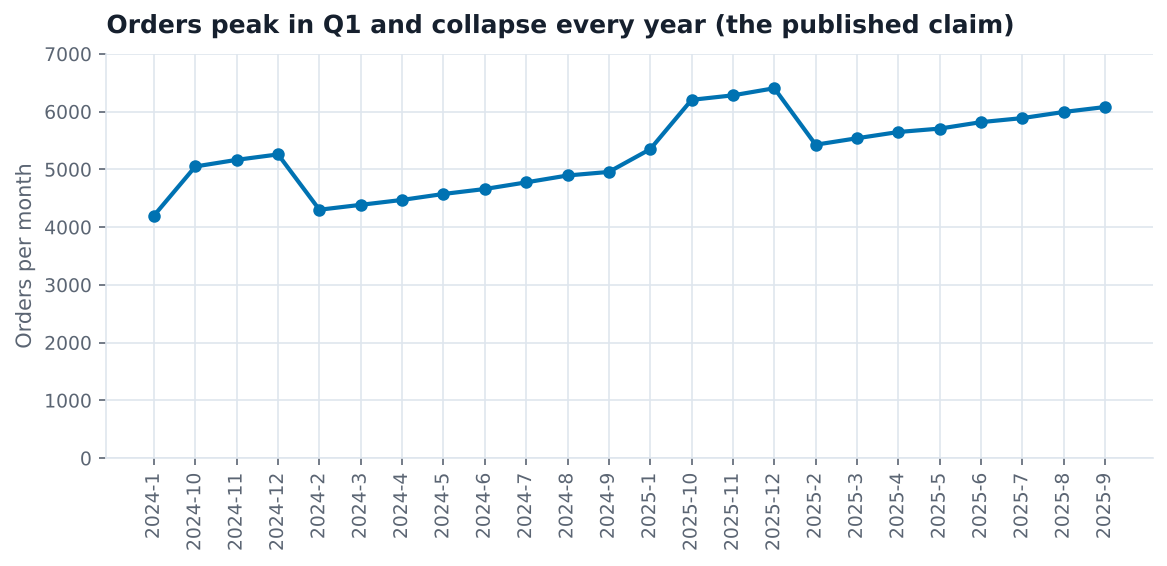

In [3]:
fig, ax = plt.subplots(figsize=(9, 3.5))
ax.plot(c1["month"], c1["orders"], marker="o", color=blue)
ax.set_ylim(0, 7000)
ax.set_title("Orders peak in Q1 and collapse every year (the published claim)")
ax.set_ylabel("Orders per month")
ax.tick_params(axis="x", rotation=90)
fig.savefig(OUT + "A1_rebuild.png", dpi=300, bbox_inches="tight")
plt.show()

Self-check: 24 points, the line climbs for 4 points, drops **958**, climbs for 11, drops **978**. ✔

Now the checks. What type is the `month` column, and are there really 24 different months?

In [4]:
print("dtype of month:", c1["month"].dtype)
print("unique months:", c1["month"].nunique())
print("branches:", c1["branch"].unique())

c1["date"] = pd.to_datetime(c1["month"], format="%Y-%m")
c1 = c1.sort_values("date")

print("smallest month-to-month change after a real date sort:", c1["orders"].diff().min())
print("Jan 2024:", c1["orders"].iloc[0], "   Dec 2025:", c1["orders"].iloc[-1])

wrong_place = (c1["date"].dt.month >= 10).sum()
print("rows moved by the text sort (months 10, 11, 12):", wrong_place)

dtype of month: str
unique months: 24
branches: <StringArray>
['Gulberg']
Length: 1, dtype: str
smallest month-to-month change after a real date sort: 59.0
Jan 2024: 4200    Dec 2025: 6405
rows moved by the text sort (months 10, 11, 12): 6


**Conclusion the chart invites:** orders rise through the "first part" of each year and then fall off a cliff, so there is a yearly cycle with a Q1 peak.

**Decoy:** my first thought was "maybe it is one branch's data mixed with another branch", or a real seasonal drop. Ruled out: there is only one branch (`Gulberg`) and all 24 months are different months, so nothing is mixed or double counted.

**Mechanism:** the `month` column is **text** (`str`) written `YYYY-M` with no zero padding, so sorting it sorts letters, not dates: `"2024-10" < "2024-2"`. The **6 rows** for October, November and December of each year get pulled in between January and February. The "drop of 958" is really December 2024 (5,259) → February 2024 — a jump *backwards in time*. After parsing with `format="%Y-%m"` the smallest monthly change is **+59**: orders went up every single month, from 4,200 to 6,405.

**Redesign:** parse the dates first, then plot on a real date axis.

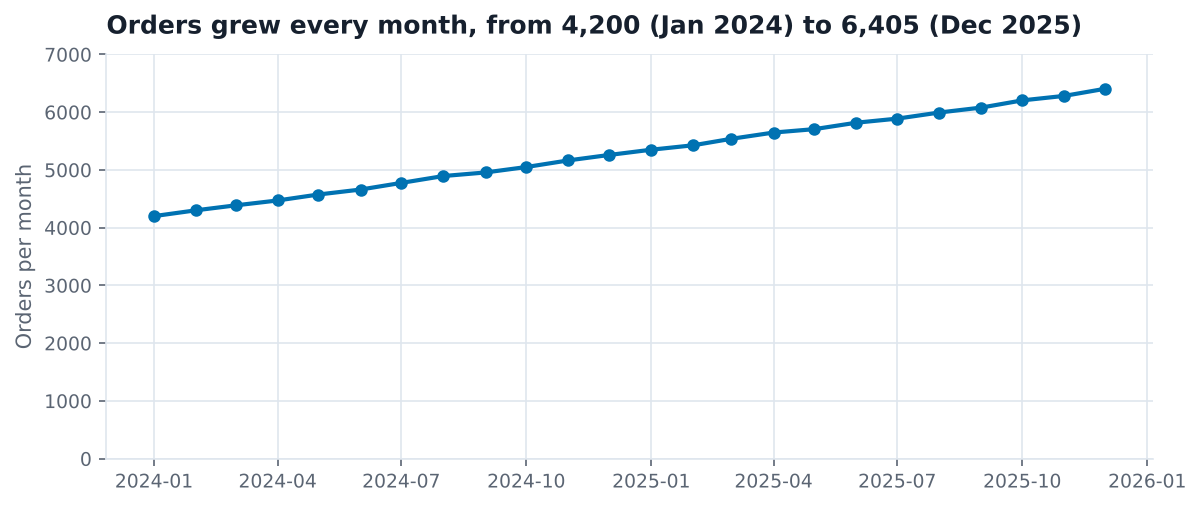

In [5]:
fig, ax = plt.subplots(figsize=(9, 3.5))
ax.plot(c1["date"], c1["orders"], marker="o", color=blue)
ax.set_ylim(0, 7000)
ax.set_title("Orders grew every month, from 4,200 (Jan 2024) to 6,405 (Dec 2025)")
ax.set_ylabel("Orders per month")
fig.savefig(OUT + "A1_redesign.png", dpi=300, bbox_inches="tight")
plt.show()

## Case 2 · "Sales grew steadily, 22%, across the quarter"

**Recipe:** plot `sales_pkr_k` against the row number, add a least-squares trend line.

In [6]:
c2 = pd.read_csv(DATA + "case02_shop_closed.csv")

x = np.arange(len(c2))
slope, intercept = np.polyfit(x, c2["sales_pkr_k"], 1)

first = c2["sales_pkr_k"].iloc[0]
last = c2["sales_pkr_k"].iloc[-1]
print("points:", len(c2), " first:", first, " last:", last, " change:", round((last / first - 1) * 100, 1), "%")

points: 69  first: 207  last: 253  change: 22.2 %


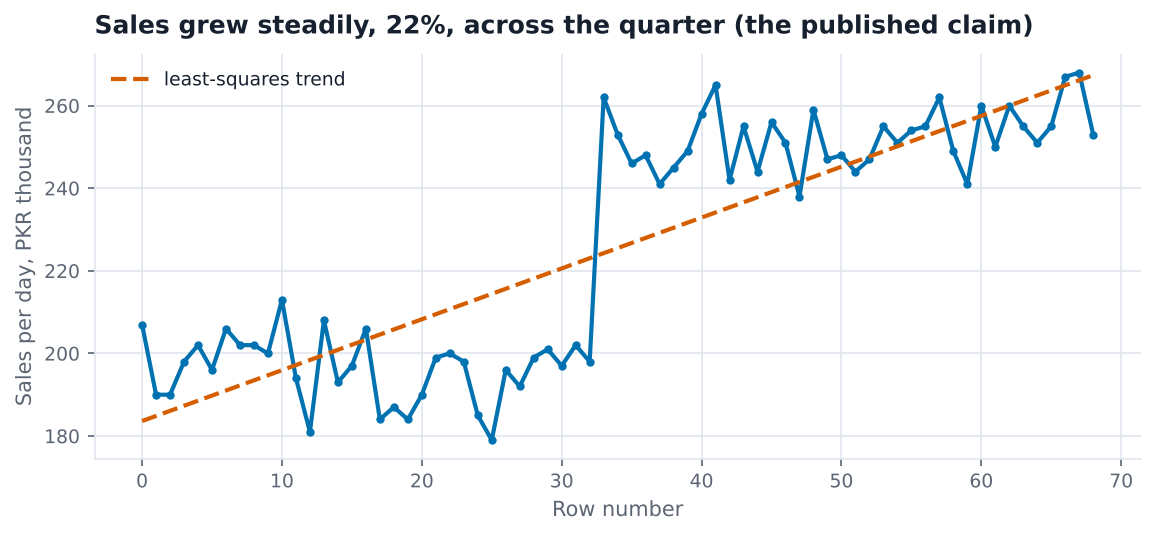

In [7]:
fig, ax = plt.subplots(figsize=(9, 3.5))
ax.plot(x, c2["sales_pkr_k"], marker="o", markersize=3, color=blue)
ax.plot(x, slope * x + intercept, color=orange, linestyle="--", label="least-squares trend")
ax.set_title("Sales grew steadily, 22%, across the quarter (the published claim)")
ax.set_xlabel("Row number")
ax.set_ylabel("Sales per day, PKR thousand")
ax.legend()
fig.savefig(OUT + "A2_rebuild.png", dpi=300, bbox_inches="tight")
plt.show()

Self-check: 69 points, first 207, last 253, +22%. ✔

The cheapest test: compare `len(df)` with the span of the date column.

In [8]:
c2["date"] = pd.to_datetime(c2["date"])
c2 = c2.set_index("date")

span = (c2.index.max() - c2.index.min()).days + 1
print("rows:", len(c2), "  days in the span:", span)

audit = tslib.audit_index(c2, "D")
print(audit)

rows: 69   days in the span: 90
{'dtype_ok': True, 'monotonic': True, 'n_rows': 69, 'n_duplicated': 0, 'n_missing': 21, 'missing_dates': ['2025-02-03 00:00:00', '2025-02-04 00:00:00', '2025-02-05 00:00:00', '2025-02-06 00:00:00', '2025-02-07 00:00:00', '2025-02-08 00:00:00', '2025-02-09 00:00:00', '2025-02-10 00:00:00', '2025-02-11 00:00:00', '2025-02-12 00:00:00', '2025-02-13 00:00:00', '2025-02-14 00:00:00'], 'span': ('2025-01-01 00:00:00', '2025-03-31 00:00:00'), 'partial_tail': False, 'tail_period': '2025-03', 'tail_count': 31}


In [9]:
print("mean sales by weekday:")
print(c2.groupby(c2.index.day_name())["sales_pkr_k"].mean().round(1))

before = c2.loc[:"2025-02-02", "sales_pkr_k"]
after = c2.loc["2025-02-24":, "sales_pkr_k"]
print("before the gap: mean", round(before.mean(), 1), " slope per day", round(np.polyfit(np.arange(len(before)), before, 1)[0], 2))
print("after the gap:  mean", round(after.mean(), 1), " slope per day", round(np.polyfit(np.arange(len(after)), after, 1)[0], 2))
print("step:", round((after.mean() / before.mean() - 1) * 100, 1), "%")

mean sales by weekday:
date
Friday       222.4
Monday       226.9
Saturday     223.8
Sunday       224.3
Thursday     225.4
Tuesday      231.9
Wednesday    224.5
Name: sales_pkr_k, dtype: float64
before the gap: mean 196.2  slope per day -0.16
after the gap:  mean 252.3  slope per day 0.23
step: 28.6 %


**Conclusion the chart invites:** sales climbed smoothly, a little each day, for the whole quarter.

**Decoy:** first I thought the missing days were weekends (a shop closed on Sundays would also make rows vanish). Ruled out: the 21 missing days are 3 of each weekday, and the weekday means are all between 222 and 232 — there is no weekly pattern at all.

**Mechanism:** plotting by **row number** deletes the days that were never recorded. The span is **90 days** but there are only **69 rows**: the shop was shut for **21 days in a row (3–23 February)**. On the row axis that 3-week closure is squeezed to zero width. Inside each part, sales are basically flat (−0.16 per day before, +0.23 per day after). What really happened is a **step**: about 196 before the closure and 252 after (+28.6%). The straight trend line turns one jump into a "steady" climb.

**Redesign:** put the calendar back (`reindex_full`), let the line break over the gap, and show the two levels.

missing days now shown as gaps: 21


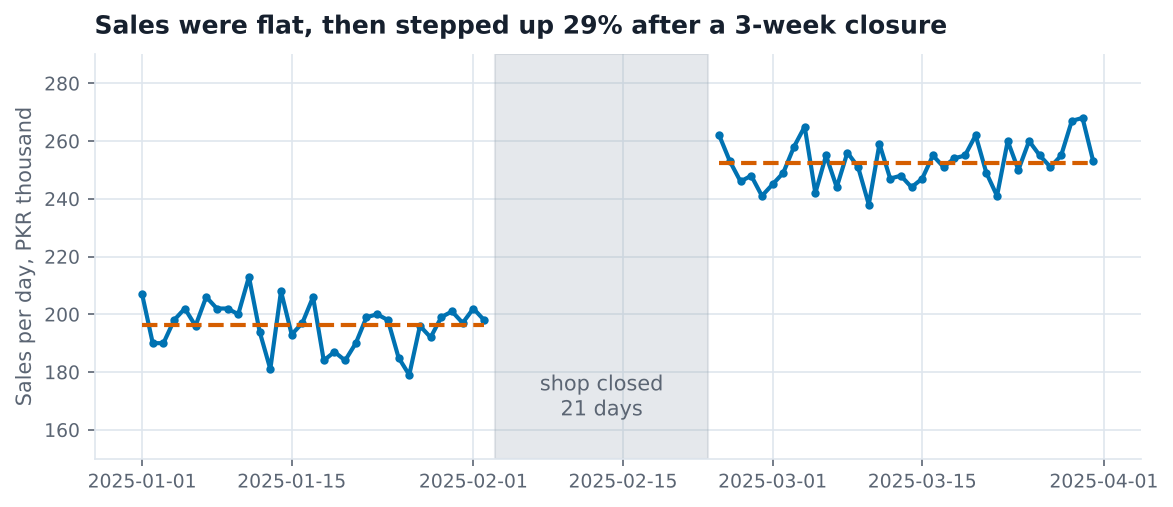

In [10]:
full = tslib.reindex_full(c2["sales_pkr_k"], "D")
print("missing days now shown as gaps:", full.isna().sum())

fig, ax = plt.subplots(figsize=(9, 3.5))
ax.plot(full.index, full.values, marker="o", markersize=3, color=blue)
ax.axvspan(pd.Timestamp("2025-02-03"), pd.Timestamp("2025-02-23"), color=grey, alpha=0.25)
ax.text(pd.Timestamp("2025-02-13"), 165, "shop closed\n21 days", ha="center", color=PALETTE["ink_soft"])
ax.hlines(before.mean(), before.index.min(), before.index.max(), color=orange, linestyle="--")
ax.hlines(after.mean(), after.index.min(), after.index.max(), color=orange, linestyle="--")
ax.set_ylim(150, 290)
ax.set_title("Sales were flat, then stepped up 29% after a 3-week closure")
ax.set_ylabel("Sales per day, PKR thousand")
fig.savefig(OUT + "A2_redesign.png", dpi=300, bbox_inches="tight")
plt.show()

(This is a line chart, not bars, so the y-axis does not need to start at zero; dashed lines are the mean of each part.)

## Case 3 · "Peak load jumped 43% overnight on 1 July"

**Recipe:** resample `concurrent_users` to daily with `.sum()`, line from zero.

In [11]:
c3 = pd.read_csv(DATA + "case03_bandwidth_levels.csv")
c3["ts"] = pd.to_datetime(c3["ts"])
c3 = c3.set_index("ts")

daily_sum = c3["concurrent_users"].resample("D").sum()
june = daily_sum["2025-06"].mean()
july = daily_sum["2025-07"].mean()
print("June daily mean:", round(june), " July daily mean:", round(july), " change:", round((july / june - 1) * 100, 1), "%")

June daily mean: 8782  July daily mean: 12543  change: 42.8 %


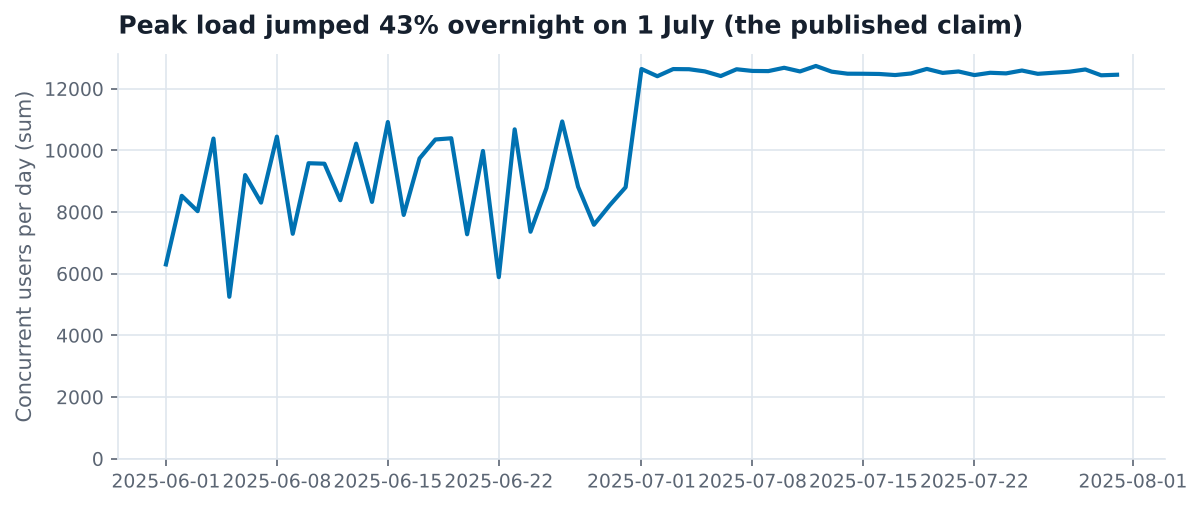

In [12]:
fig, ax = plt.subplots(figsize=(9, 3.5))
ax.plot(daily_sum.index, daily_sum.values, color=blue)
ax.set_ylim(0, None)
ax.set_title("Peak load jumped 43% overnight on 1 July (the published claim)")
ax.set_ylabel("Concurrent users per day (sum)")
fig.savefig(OUT + "A3_rebuild.png", dpi=300, bbox_inches="tight")
plt.show()

Self-check: June ≈ 8,800, July ≈ 12,500, +43%. ✔

In [13]:
print(tslib.audit_index(c3, "h"))

hours = c3["concurrent_users"].resample("D").count()
print("hours recorded per day — June mean:", round(hours["2025-06"].mean(), 1), " July mean:", round(hours["2025-07"].mean(), 1))

daily_mean = c3["concurrent_users"].resample("D").mean()
daily_peak = c3["concurrent_users"].resample("D").max()
print("mean users per hour — June:", round(daily_mean["2025-06"].mean()), " July:", round(daily_mean["2025-07"].mean()))
print("daily peak users   — June:", round(daily_peak["2025-06"].mean()), " July:", round(daily_peak["2025-07"].mean()))

{'dtype_ok': True, 'monotonic': True, 'n_rows': 1237, 'n_duplicated': 0, 'n_missing': 227, 'missing_dates': ['2025-06-01 12:00:00', '2025-06-01 13:00:00', '2025-06-01 14:00:00', '2025-06-01 15:00:00', '2025-06-01 16:00:00', '2025-06-01 17:00:00', '2025-06-01 18:00:00', '2025-06-01 19:00:00', '2025-06-01 20:00:00', '2025-06-01 21:00:00', '2025-06-02 13:00:00', '2025-06-02 14:00:00'], 'span': ('2025-06-01 00:00:00', '2025-07-31 23:00:00'), 'partial_tail': False, 'tail_period': '2025-07-31', 'tail_count': 24}
hours recorded per day — June mean: 16.4  July mean: 24.0
mean users per hour — June: 536  July: 523
daily peak users   — June: 779  July: 808


**Conclusion the chart invites:** something happened on 1 July (a launch, a campaign) and the load on the servers jumped by 43%.

**Decoy:** my first idea was "the sum is fine, it is just a total of users". Ruled out: `concurrent_users` is a **level** — the number connected *at that instant*. Adding up 24 snapshots does not count anything real; the same user is counted in every hour they stay online.

**Mechanism:** a level resampled with `sum()` measures **how many readings exist**, not the load. `audit_index` finds **227 missing hours**, all in June: June days have only **16.4 hours** recorded on average, July days have **24**. That ratio (24 / 16.4 ≈ 1.46) is the whole "43% jump". The real load hardly moved: mean users per hour went 536 → 523 (−2.4%), and the average daily peak went 779 → 808 (+3.7%) — nowhere near +43%.

**Redesign:** resample the level with `max()` (peak load is what the claim is about) and show the number of hours behind each day in a second panel — not a second y-axis.

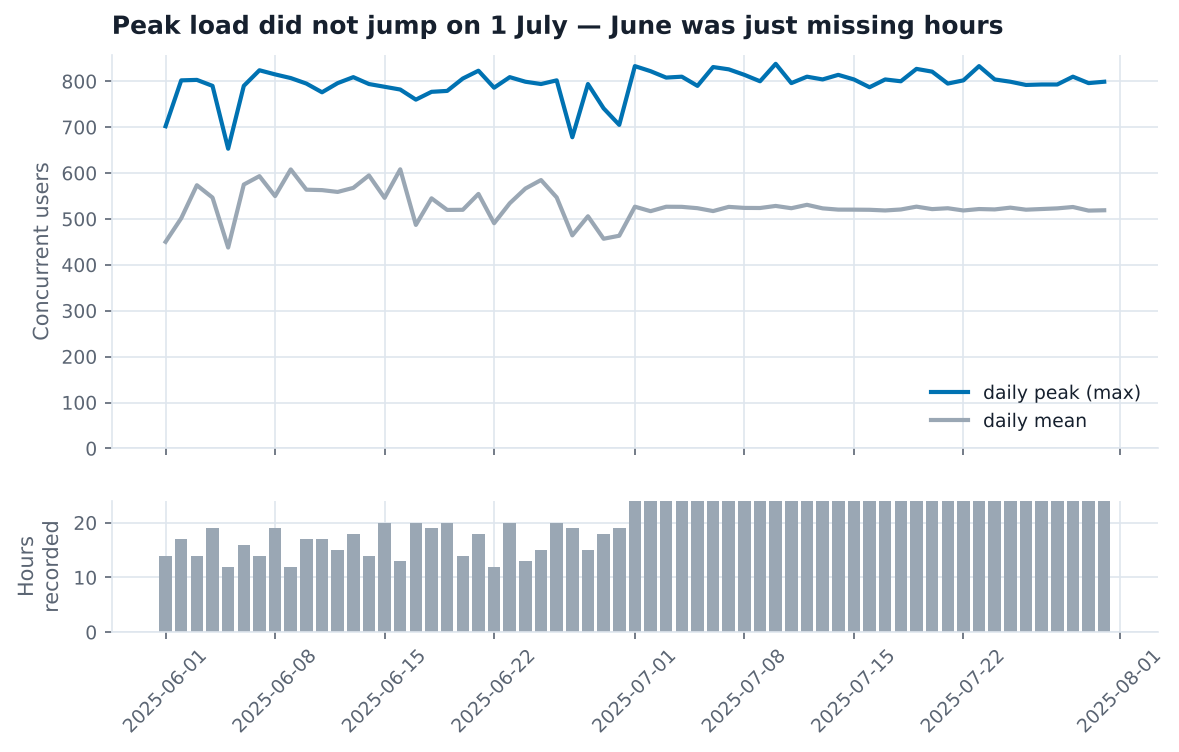

In [14]:
fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(9, 5), sharex=True, gridspec_kw={"height_ratios": [3, 1]})

ax1.plot(daily_peak.index, daily_peak.values, color=blue, label="daily peak (max)")
ax1.plot(daily_mean.index, daily_mean.values, color=grey, label="daily mean")
ax1.set_ylim(0, None)
ax1.set_ylabel("Concurrent users")
ax1.set_title("Peak load did not jump on 1 July — June was just missing hours")
ax1.legend(loc="lower right")

ax2.bar(hours.index, hours.values, color=grey)
ax2.set_ylim(0, 24)
ax2.set_ylabel("Hours\nrecorded")
ax2.tick_params(axis="x", rotation=45)

fig.savefig(OUT + "A3_redesign.png", dpi=300, bbox_inches="tight")
plt.show()

## Case 4 · "The new checkout flow started working on 7 September"

**Recipe:** raw in grey, 31-day **trailing** rolling mean on top, mark its turning point.

In [15]:
c4 = pd.read_csv(DATA + "case04_intervention_lag.csv")
c4["date"] = pd.to_datetime(c4["date"])
c4 = c4.set_index("date")["conversion_pct"]

trailing = c4.rolling(31).mean()
turn = trailing.idxmin()
print("trailing mean bottoms out on:", turn.date())

trailing mean bottoms out on: 2025-09-07


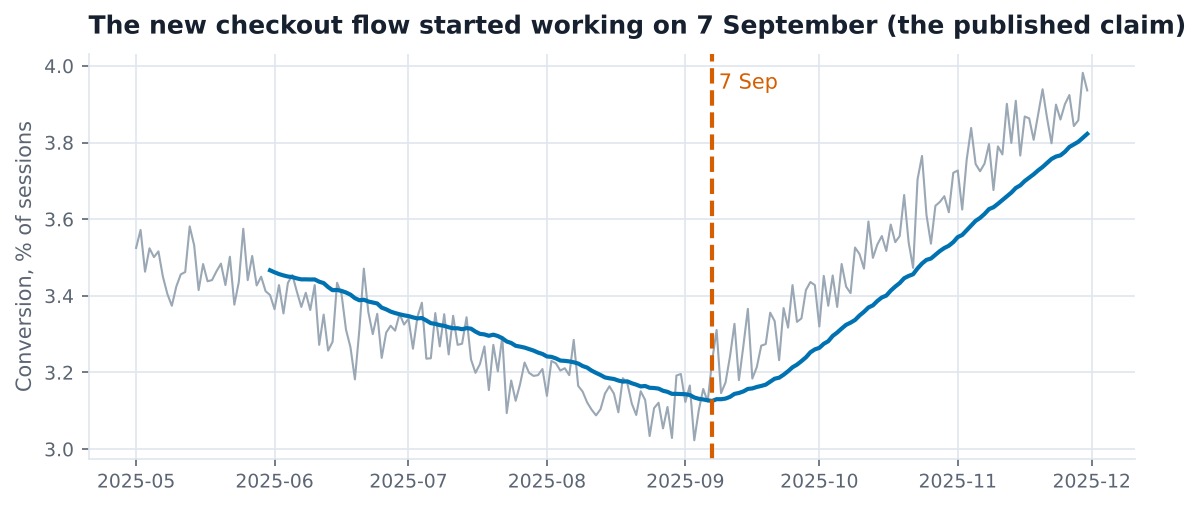

In [16]:
fig, ax = plt.subplots(figsize=(9, 3.5))
ax.plot(c4.index, c4.values, color=grey, linewidth=1)
ax.plot(trailing.index, trailing.values, color=blue)
ax.axvline(turn, color=orange, linestyle="--")
ax.text(turn, c4.max(), " 7 Sep", color=orange, va="top")
ax.set_title("The new checkout flow started working on 7 September (the published claim)")
ax.set_ylabel("Conversion, % of sessions")
fig.savefig(OUT + "A4_rebuild.png", dpi=300, bbox_inches="tight")
plt.show()

Self-check: trailing mean bottoms out on 2025-09-07. ✔

In [17]:
lag = tslib.lag_at_turn(c4, 31, how="min")
print(lag)

weekly = c4.resample("W").mean().round(3)
print(weekly["2025-08":"2025-09"])

{'window': 31, 'trailing_turn': Timestamp('2025-09-07 00:00:00'), 'centred_turn': Timestamp('2025-08-23 00:00:00'), 'lag_periods': 15, 'half_window': 15}
date
2025-08-03    3.198
2025-08-10    3.190
2025-08-17    3.121
2025-08-24    3.125
2025-08-31    3.116
2025-09-07    3.132
2025-09-14    3.236
2025-09-21    3.285
2025-09-28    3.348
Freq: W-SUN, Name: conversion_pct, dtype: float64


**Conclusion the chart invites:** the new checkout started to lift conversion on 7 September.

**Decoy:** first I thought "the raw data is too noisy to tell when it turned, so the smoothed date is as good as any". Ruled out: the weekly means of the raw data sit flat at about **3.12%** for the weeks ending 17, 24 and 31 August, then climb every week (3.13, 3.24, 3.29, 3.35). So there is a real turn — the only question is *when* the chart says it was.

**Mechanism:** a **trailing** mean is an average of the *last* 31 days, so each point is centred about 15 days in the past. Its turning point arrives half a window late. `lag_at_turn` shows the centred 31-day mean bottoms on **2025-08-23**, and the trailing one on **2025-09-07** — a lag of **15 days**, which is exactly the half-window (31 // 2 = 15). So the turn happened in late August, and if the launch was on 7 September the chart is giving it credit for an improvement that started two weeks before it.

**Redesign:** same chart, but with a **centred** window, the window named, and the trailing line kept faintly for comparison.

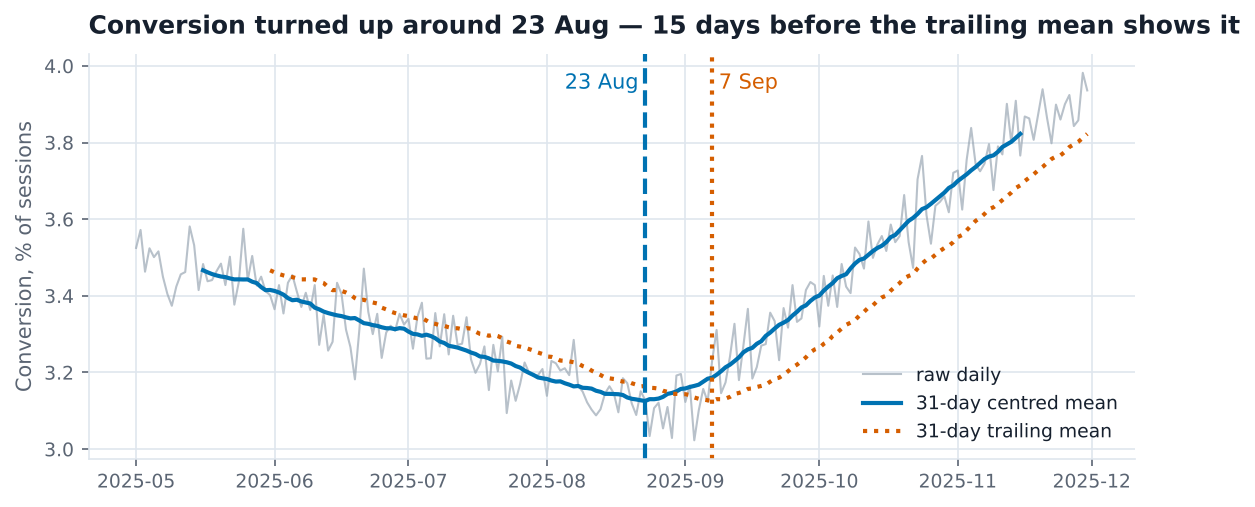

In [18]:
centred = c4.rolling(31, center=True).mean()
c_turn = centred.idxmin()

fig, ax = plt.subplots(figsize=(9, 3.5))
ax.plot(c4.index, c4.values, color=grey, linewidth=1, alpha=0.7, label="raw daily")
ax.plot(centred.index, centred.values, color=blue, label="31-day centred mean")
ax.plot(trailing.index, trailing.values, color=orange, linestyle=":", label="31-day trailing mean")
ax.axvline(c_turn, color=blue, linestyle="--")
ax.axvline(turn, color=orange, linestyle=":")
ax.text(c_turn, c4.max(), "23 Aug ", color=blue, ha="right", va="top")
ax.text(turn, c4.max(), " 7 Sep", color=orange, va="top")
ax.set_title("Conversion turned up around 23 Aug — 15 days before the trailing mean shows it")
ax.set_ylabel("Conversion, % of sessions")
ax.legend(loc="lower right")
fig.savefig(OUT + "A4_redesign.png", dpi=300, bbox_inches="tight")
plt.show()

## Case 5 · "Revenue has fallen for six straight months"

**Recipe:** May to November 2025 only, line with markers, y from zero.

In [19]:
c5 = pd.read_csv(DATA + "case05_revenue_window.csv")
c5["month"] = pd.to_datetime(c5["month"])
c5 = c5.set_index("month")["revenue_pkr_m"]

window = c5["2025-05":"2025-11"]
print(window.round(1).tolist())
print("change:", round((window.iloc[-1] / window.iloc[0] - 1) * 100, 1), "%")

[158.8, 158.1, 143.8, 129.3, 108.0, 93.2, 92.2]
change: -41.9 %


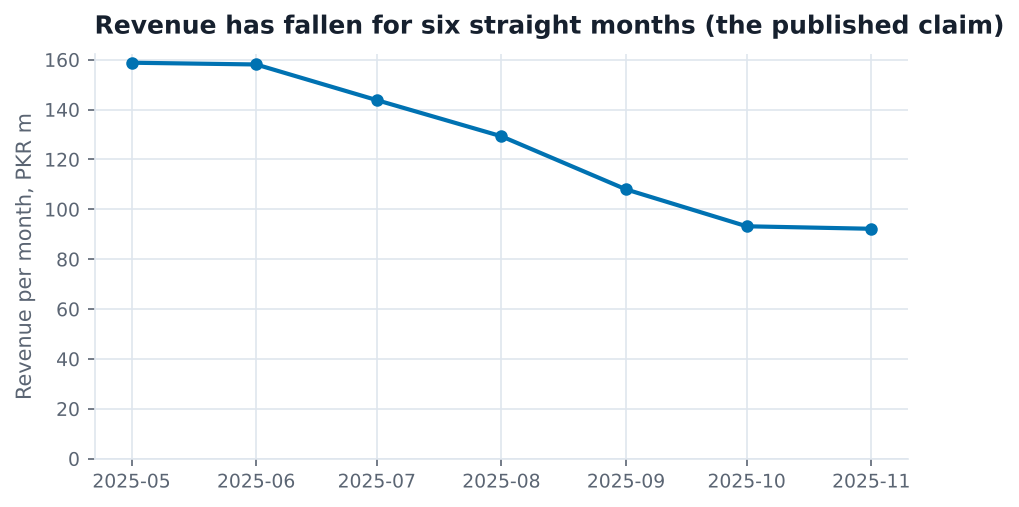

In [20]:
fig, ax = plt.subplots(figsize=(7, 3.5))
ax.plot(window.index, window.values, marker="o", color=blue)
ax.set_ylim(0, None)
ax.set_title("Revenue has fallen for six straight months (the published claim)")
ax.set_ylabel("Revenue per month, PKR m")
fig.savefig(OUT + "A5_rebuild.png", dpi=300, bbox_inches="tight")
plt.show()

Self-check: 7 points, 158.8 → 92.2, −41.9%. ✔

In [21]:
print("months in the file:", len(c5), " from", c5.index.min().date(), "to", c5.index.max().date())

for year in [2023, 2024, 2025]:
    w = c5[f"{year}-05":f"{year}-11"]
    print(year, "May -> Nov:", round((w.iloc[-1] / w.iloc[0] - 1) * 100, 1), "%")

print("\naverage revenue by calendar month:")
print(c5.groupby(c5.index.month).mean().round(1).to_dict())

print("\nyearly totals:", c5.groupby(c5.index.year).sum().round(1).to_dict())
print("Nov 2025 vs Nov 2024:", round((c5["2025-11"].iloc[0] / c5["2024-11"].iloc[0] - 1) * 100, 1), "%")

months in the file: 36  from 2023-01-01 to 2025-12-01
2023 May -> Nov: -42.4 %
2024 May -> Nov: -42.8 %
2025 May -> Nov: -41.9 %

average revenue by calendar month:
{1: 92.3, 2: 112.4, 3: 128.4, 4: 140.6, 5: 145.8, 6: 144.3, 7: 132.1, 8: 117.7, 9: 97.2, 10: 87.6, 11: 84.0, 12: 88.5}

yearly totals: {2023: 1254.7, 2024: 1361.9, 2025: 1496.3}
Nov 2025 vs Nov 2024: 9.2 %


**Conclusion the chart invites:** the business is in a six-month decline and revenue is down by 42%.

**Decoy:** the axis is not truncated (it starts at zero, as the recipe says), and the sample is not small: the file has **36 complete months**. The analyst had all of them and chose to show 7.

**Mechanism:** the window **starts at the seasonal peak and ends near the trough**. May is the highest month on average (145.8) and November is one of the lowest (84.0). The same May→November fall happens every year: **−42.4% in 2023, −42.8% in 2024, −41.9% in 2025**. So the "decline" is just the normal season. Year on year, November 2025 is **+9.2%** above November 2024, and yearly totals rose 1,254.7 → 1,361.9 → 1,496.3.

**Redesign:** show all 36 months with the chosen window shaded, and a cycle plot so each year can be compared to the one before.

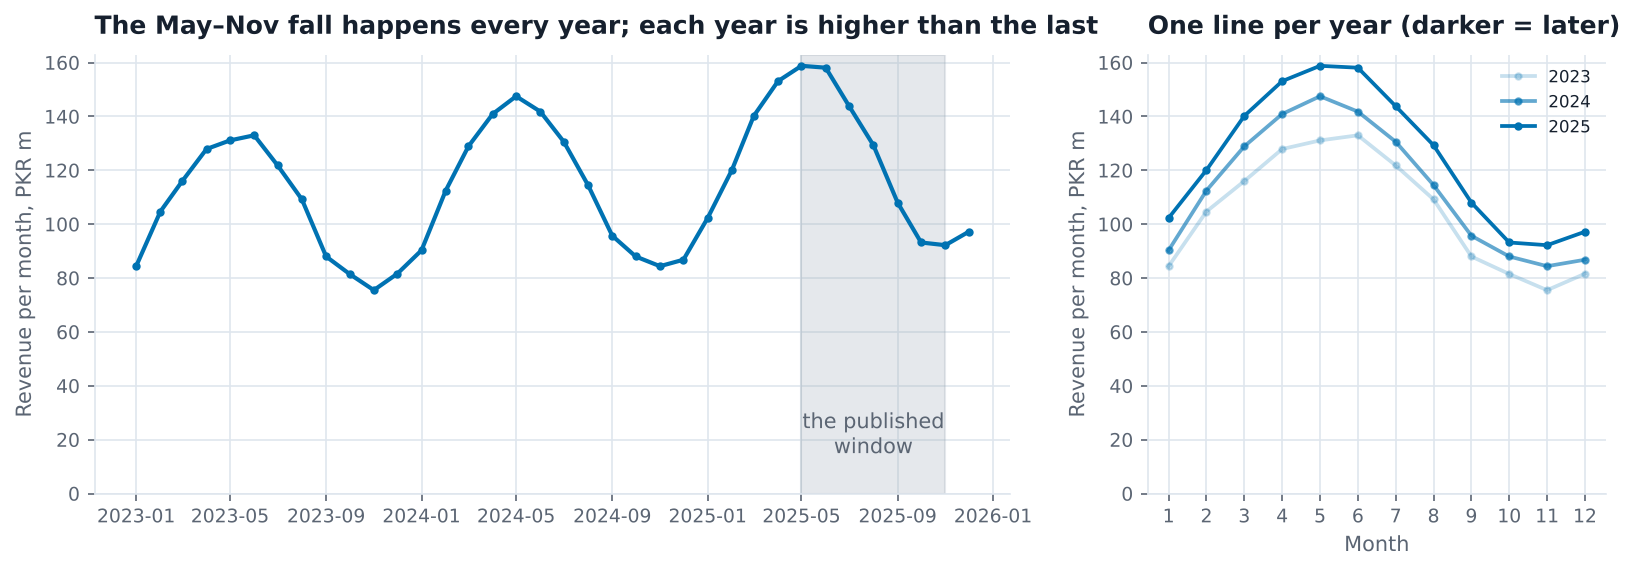

In [22]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(13, 3.8), gridspec_kw={"width_ratios": [2, 1]})

ax1.plot(c5.index, c5.values, marker="o", markersize=3, color=blue)
ax1.axvspan(pd.Timestamp("2025-05-01"), pd.Timestamp("2025-11-01"), color=grey, alpha=0.25)
ax1.text(pd.Timestamp("2025-08-01"), 15, "the published\nwindow", ha="center", color=PALETTE["ink_soft"])
ax1.set_ylim(0, None)
ax1.set_ylabel("Revenue per month, PKR m")
ax1.set_title("The May–Nov fall happens every year; each year is higher than the last")

tslib.cycle_plot(ax2, c5, by="month")
ax2.set_ylim(0, None)
ax2.set_ylabel("Revenue per month, PKR m")
ax2.set_title("One line per year (darker = later)")
ax2.legend(fontsize=8)

fig.savefig(OUT + "A5_redesign.png", dpi=300, bbox_inches="tight")
plt.show()

## Case 6 · "Orders collapsed in October"

**Recipe:** resample `orders` to monthly totals with `.sum()`, bars from zero.

In [23]:
c6 = pd.read_csv(DATA + "case06_monthly_partial.csv")
c6["date"] = pd.to_datetime(c6["date"])
c6 = c6.set_index("date")["orders"]

monthly = c6.resample("MS").sum()
print(monthly)
print("October as % of September:", round(monthly.iloc[-1] / monthly.iloc[-2] * 100), "%")

date
2025-01-01     9484
2025-02-01     8659
2025-03-01     9818
2025-04-01     9884
2025-05-01    10349
2025-06-01    10198
2025-07-01    10884
2025-08-01    11042
2025-09-01    10805
2025-10-01     4041
Freq: MS, Name: orders, dtype: int64
October as % of September: 37 %


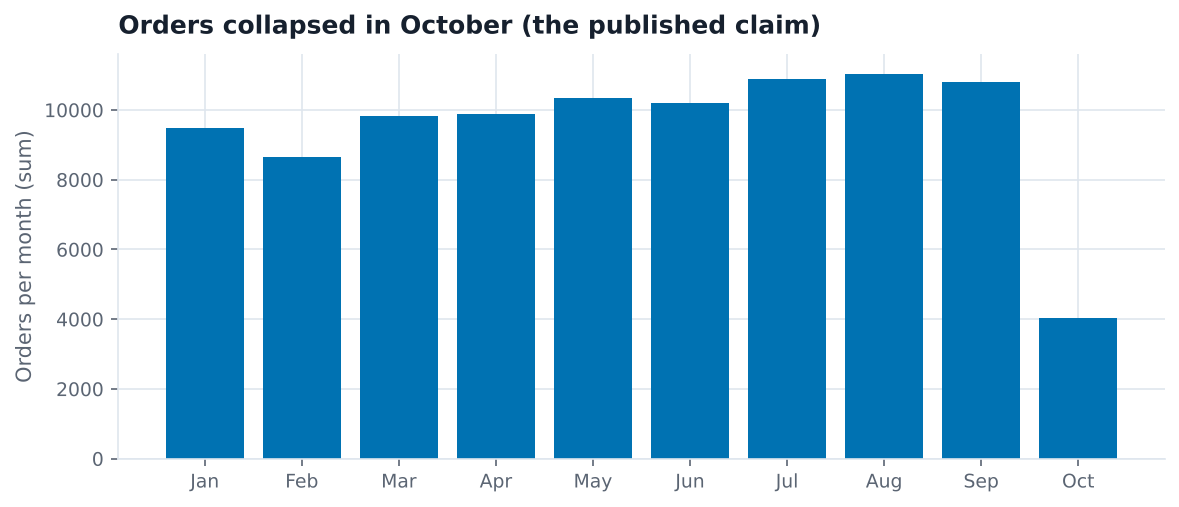

In [24]:
fig, ax = plt.subplots(figsize=(9, 3.5))
ax.bar(monthly.index.strftime("%b"), monthly.values, color=blue)
ax.set_title("Orders collapsed in October (the published claim)")
ax.set_ylabel("Orders per month (sum)")
fig.savefig(OUT + "A6_rebuild.png", dpi=300, bbox_inches="tight")
plt.show()

Self-check: ten bars, September 10,805, October 4,041 (37%). ✔

In [25]:
print(tslib.audit_index(c6, "D"))

days = c6.resample("MS").count()
per_day = (monthly / days).round(1)
print(pd.DataFrame({"orders": monthly, "days": days, "orders_per_day": per_day}))

{'dtype_ok': True, 'monotonic': True, 'n_rows': 284, 'n_duplicated': 0, 'n_missing': 0, 'missing_dates': [], 'span': ('2025-01-01 00:00:00', '2025-10-11 00:00:00'), 'partial_tail': True, 'tail_period': '2025-10', 'tail_count': 11}
            orders  days  orders_per_day
date                                    
2025-01-01    9484    31           305.9
2025-02-01    8659    28           309.2
2025-03-01    9818    31           316.7
2025-04-01    9884    30           329.5
2025-05-01   10349    31           333.8
2025-06-01   10198    30           339.9
2025-07-01   10884    31           351.1
2025-08-01   11042    31           356.2
2025-09-01   10805    30           360.2
2025-10-01    4041    11           367.4


**Conclusion the chart invites:** demand fell off a cliff in October, to about a third of September.

**Decoy:** first I suspected missing or duplicated days in October. Ruled out: `audit_index` finds **0 duplicates and 0 missing days** inside the range — every day that is in the file is complete.

**Mechanism:** an **incomplete final period**. The extract stops on **11 October**, so October has **11 days** against 30 or 31 for every other month (`partial_tail = True`). A monthly *sum* compares 11 days to 30. Per day, October is **367.4 orders/day — the highest of the year** (September was 360.2). Orders per day went up every month.

**Redesign:** compare months on orders **per day**, and mark October as partial.

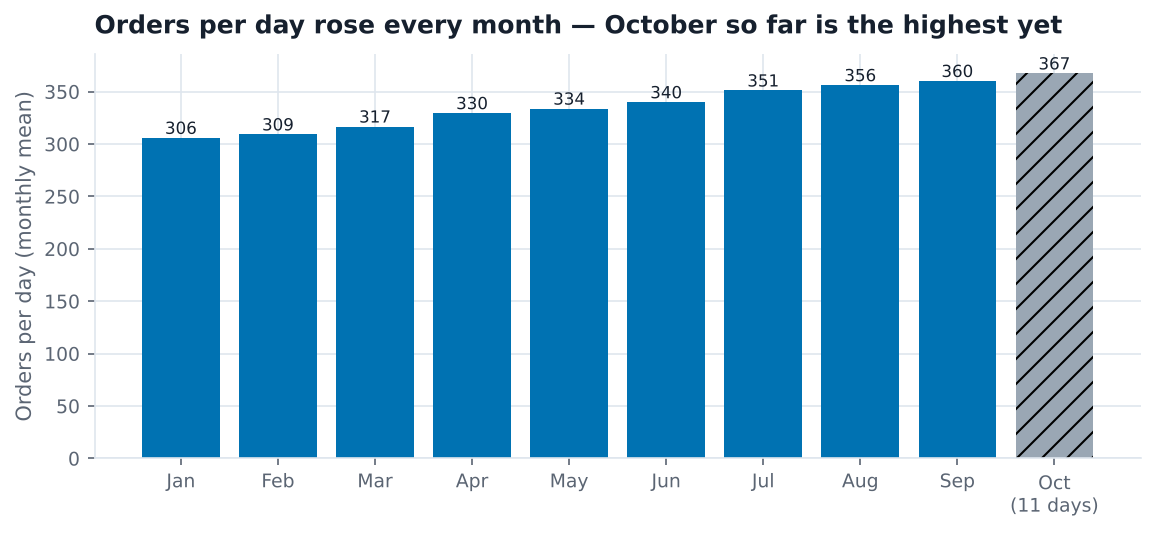

In [26]:
labels = list(monthly.index.strftime("%b"))
labels[-1] = "Oct\n(11 days)"
colors = [blue] * (len(per_day) - 1) + [grey]

fig, ax = plt.subplots(figsize=(9, 3.5))
bars = ax.bar(labels, per_day.values, color=colors)
bars[-1].set_hatch("//")
ax.bar_label(bars, fmt="%.0f", fontsize=8)
ax.set_title("Orders per day rose every month — October so far is the highest yet")
ax.set_ylabel("Orders per day (monthly mean)")
fig.savefig(OUT + "A6_redesign.png", dpi=300, bbox_inches="tight")
plt.show()

## Case 7 · "Product D has been erratic since mid-2024"

**Recipe:** stacked area of the four products, `product_a` at the bottom, `product_d` on top.

In [27]:
c7 = pd.read_csv(DATA + "case07_stacked_products.csv")
c7["month"] = pd.to_datetime(c7["month"])
c7 = c7.set_index("month")

total = c7.sum(axis=1)
print("total envelope:", round(total.min(), 1), "to", round(total.max(), 1))

total envelope: 548.3 to 708.7


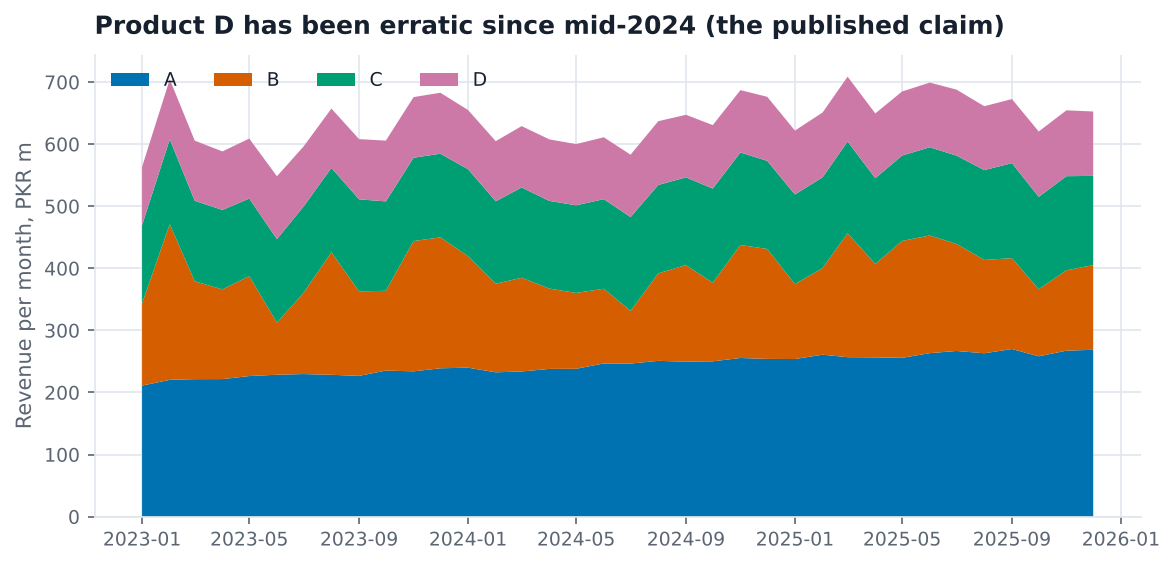

In [28]:
fig, ax = plt.subplots(figsize=(9, 4))
ax.stackplot(c7.index, c7["product_a"], c7["product_b"], c7["product_c"], c7["product_d"],
             labels=["A", "B", "C", "D"], colors=[blue, orange, green, pink])
ax.set_title("Product D has been erratic since mid-2024 (the published claim)")
ax.set_ylabel("Revenue per month, PKR m")
ax.legend(loc="upper left", ncol=4)
fig.savefig(OUT + "A7_rebuild.png", dpi=300, bbox_inches="tight")
plt.show()

Self-check: envelope between about 548 and 709. ✔

The hint says to open the CSV. How much does **each** product move month to month?

In [29]:
changes = c7.diff()
print("std of month-to-month change, whole period:")
print(changes.std().round(1))
print("\nsince July 2024:")
print(changes["2024-07":].std().round(1))

std of month-to-month change, whole period:
product_a     4.7
product_b    45.8
product_c     6.4
product_d     2.0
dtype: float64

since July 2024:
product_a     5.1
product_b    36.3
product_c     5.8
product_d     1.8
dtype: float64


**Conclusion the chart invites:** product D (the top band) jumps around, so D is the unstable product.

**Decoy:** first I thought D might really be volatile and the stack just makes it look bigger. Ruled out by computing it: D's own month-to-month change has a standard deviation of only **2.0** — the **smallest** of the four — and it is not bigger after mid-2024 (1.8 vs 2.2 before).

**Mechanism:** in a stacked area every band sits on a **moving baseline** made of all the bands below it. The column the recipe never isolates is **`product_b`**: its month-to-month changes have a standard deviation of **45.8**, more than 20 times D's. Because B is in the middle of the stack, its swings lift and drop C and D. The wiggle we see on D's top edge is B's volatility leaking upwards.

**Redesign:** unstack — one small panel per product, each on its own zero baseline, same y scale so they can be compared.

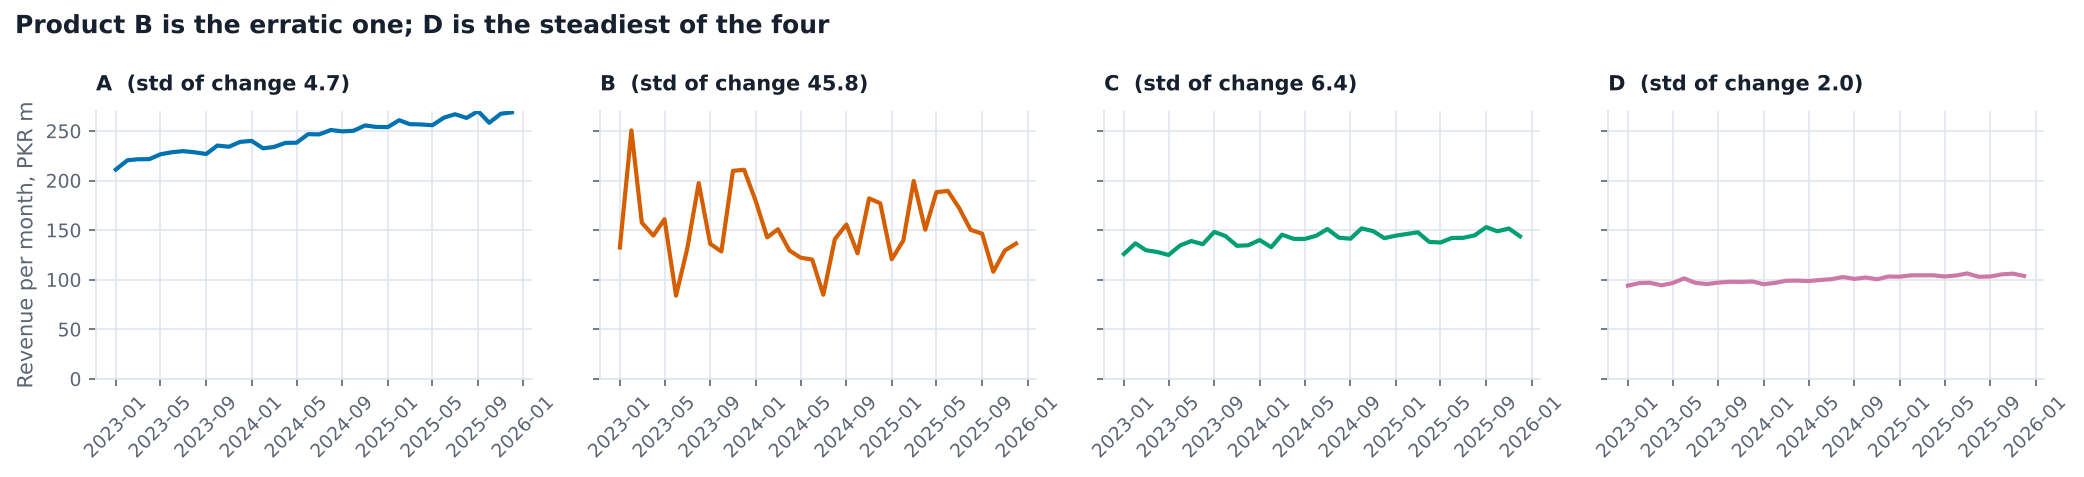

In [30]:
fig, axes = plt.subplots(1, 4, figsize=(14, 3.2), sharey=True)
names = ["product_a", "product_b", "product_c", "product_d"]
cols = [blue, orange, green, pink]

for ax, name, col in zip(axes, names, cols):
    ax.plot(c7.index, c7[name], color=col)
    ax.set_title(f"{name[-1].upper()}  (std of change {changes[name].std():.1f})", fontsize=10)
    ax.set_ylim(0, 270)
    ax.tick_params(axis="x", rotation=45)

axes[0].set_ylabel("Revenue per month, PKR m")
fig.suptitle("Product B is the erratic one; D is the steadiest of the four", x=0.01, ha="left", fontweight="bold")
fig.tight_layout()
fig.savefig(OUT + "A7_redesign.png", dpi=300, bbox_inches="tight")
plt.show()

## Case 8 · "Paid search drives 43% of our customers"

**Recipe:** count `True` in each `touch_*` column, divide by number of customers, draw a four-slice pie.

In [31]:
c8 = pd.read_csv(DATA + "case08_channel_attrib.csv")
touch = ["touch_search", "touch_social", "touch_email", "touch_direct"]

shares8 = c8[touch].sum() / len(c8) * 100
print(shares8.round(1))
print("sum of the four shares:", round(shares8.sum(), 1), "%")

touch_search    42.6
touch_social    32.3
touch_email     27.5
touch_direct    28.6
dtype: float64
sum of the four shares: 131.0 %


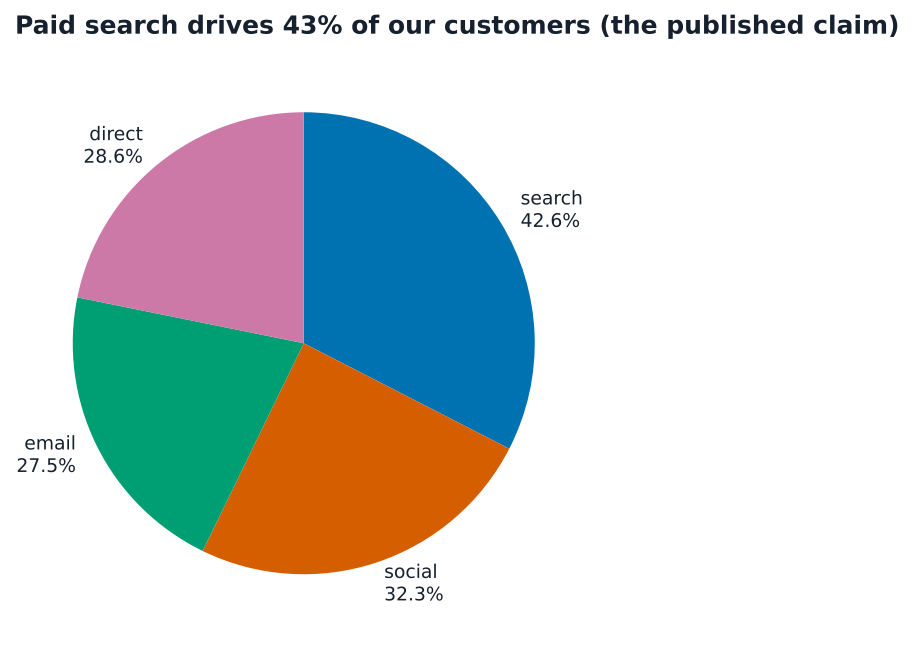

In [32]:
fig, ax = plt.subplots(figsize=(5, 5))
names8 = [t.replace("touch_", "") for t in touch]
labels8 = [f"{n}\n{v:.1f}%" for n, v in zip(names8, shares8)]
ax.pie(shares8, labels=labels8, colors=[blue, orange, green, pink], startangle=90, counterclock=False)
ax.set_title("Paid search drives 43% of our customers (the published claim)")
fig.savefig(OUT + "A8_rebuild.png", dpi=300, bbox_inches="tight")
plt.show()

Self-check: search 42.6%, social 32.3%, email 27.5%, direct 28.6%. ✔ — and they add up to **131%**.

In [33]:
check8 = tslib.exclusivity_check(c8, touch)
print(check8)

n_channels = c8[touch].sum(axis=1)
print(n_channels.value_counts().sort_index())

only_one = c8[n_channels == 1]
only_share = only_one[touch].sum() / len(c8) * 100
print("\ncustomers touched ONLY by this channel (% of all customers):")
print(only_share.round(1))

{'n': 4000, 'shares_pct': {'touch_search': 42.62, 'touch_social': 32.3, 'touch_email': 27.48, 'touch_direct': 28.58}, 'sum_pct': 130.98, 'exclusive': False, 'n_multi': 1105, 'pct_multi': 27.62, 'n_zero': 0}
1    2895
2     980
3     116
4       9
Name: count, dtype: int64

customers touched ONLY by this channel (% of all customers):
touch_search    25.9
touch_social    17.8
touch_email     13.8
touch_direct    14.8
dtype: float64


**Conclusion the chart invites:** 43% of customers came from paid search, so search is the biggest slice of the pie.

**Decoy:** my first thought was "it is just rounding, pies are always a bit off". Ruled out: the four shares add up to **131.0%**, a 31-point gap, which no rounding can make.

**Mechanism:** the parts are **not exclusive**. A customer can be touched by several channels. `exclusivity_check` shows **1,105 customers (27.6%)** were touched by 2 or more channels (980 by two, 116 by three, 9 by all four). Those customers are counted in every slice they belong to. Also, matplotlib's `pie()` silently rescales to 100%, so the search slice is drawn as 42.6 / 131 = **32.5%** of the circle while its label says 42.6% — the pie cannot even show its own number. Only **25.9%** of customers were touched by search *alone*.

**Redesign:** this is not a part-to-whole question, so no pie. Show **reach** as bars on a 0–100% scale, with the "only this channel" number next to it, and say on the chart that the bars overlap.

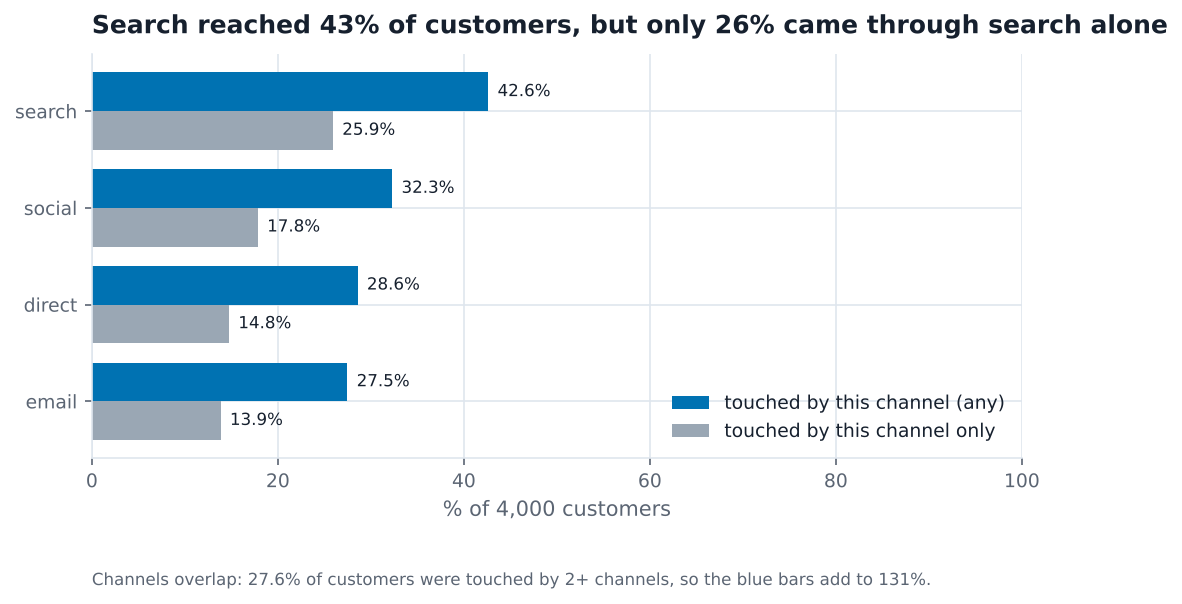

In [34]:
order = shares8.sort_values().index
y = np.arange(len(order))

fig, ax = plt.subplots(figsize=(8, 3.5))
ax.barh(y + 0.2, shares8[order], height=0.4, color=blue, label="touched by this channel (any)")
ax.barh(y - 0.2, only_share[order], height=0.4, color=grey, label="touched by this channel only")
for i, name in enumerate(order):
    ax.text(shares8[name] + 1, i + 0.2, f"{shares8[name]:.1f}%", va="center", fontsize=8)
    ax.text(only_share[name] + 1, i - 0.2, f"{only_share[name]:.1f}%", va="center", fontsize=8)
ax.set_yticks(y)
ax.set_yticklabels([n.replace("touch_", "") for n in order])
ax.set_xlim(0, 100)
ax.set_xlabel("% of 4,000 customers")
ax.set_title("Search reached 43% of customers, but only 26% came through search alone")
ax.legend(loc="lower right")
ax.text(0, -1.9, "Channels overlap: 27.6% of customers were touched by 2+ channels, so the blue bars add to 131%.",
        fontsize=8, color=PALETTE["ink_soft"])
fig.savefig(OUT + "A8_redesign.png", dpi=300, bbox_inches="tight")
plt.show()

## Case 9 · "Premium is now 38% of revenue — a record"

**Recipe:** premium / total per quarter, line from zero, annotate the last point.

In [35]:
c9 = pd.read_csv(DATA + "case09_premium_share.csv")
c9["share"] = c9["premium_revenue_pkr_m"] / c9["total_revenue_pkr_m"] * 100
print(c9.round(1))

  quarter  total_revenue_pkr_m  premium_revenue_pkr_m  share
0  2024Q1               1000.0                  240.0   24.0
1  2024Q2                940.0                  236.9   25.2
2  2024Q3                870.0                  233.2   26.8
3  2024Q4                800.0                  228.0   28.5
4  2025Q1                745.0                  227.2   30.5
5  2025Q2                700.0                  227.5   32.5
6  2025Q3                650.0                  228.8   35.2
7  2025Q4                600.0                  228.0   38.0


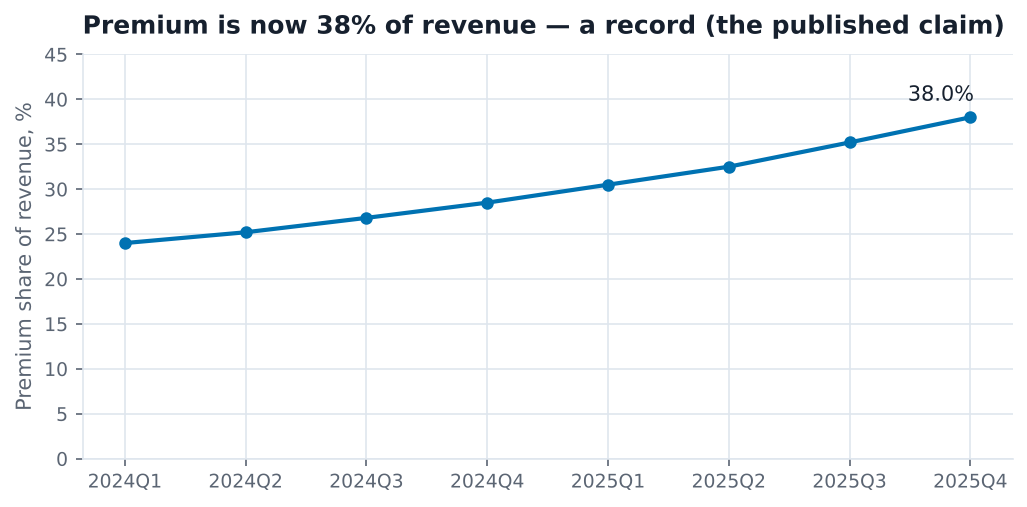

In [36]:
fig, ax = plt.subplots(figsize=(8, 3.5))
ax.plot(c9["quarter"], c9["share"], marker="o", color=blue)
ax.annotate(f"{c9['share'].iloc[-1]:.1f}%", (7, c9["share"].iloc[-1]), xytext=(-30, 8), textcoords="offset points")
ax.set_ylim(0, 45)
ax.set_title("Premium is now 38% of revenue — a record (the published claim)")
ax.set_ylabel("Premium share of revenue, %")
fig.savefig(OUT + "A9_rebuild.png", dpi=300, bbox_inches="tight")
plt.show()

Self-check: 24.0% → 38.0%. ✔

In [37]:
first9 = c9.iloc[0]
last9 = c9.iloc[-1]
print("total revenue:   ", first9["total_revenue_pkr_m"], "->", last9["total_revenue_pkr_m"],
      round((last9["total_revenue_pkr_m"] / first9["total_revenue_pkr_m"] - 1) * 100, 1), "%")
print("premium revenue: ", first9["premium_revenue_pkr_m"], "->", last9["premium_revenue_pkr_m"],
      round((last9["premium_revenue_pkr_m"] / first9["premium_revenue_pkr_m"] - 1) * 100, 1), "%")
print("premium max quarter:", c9.loc[c9["premium_revenue_pkr_m"].idxmax(), "quarter"])

total revenue:    1000.0 -> 600.0 -40.0 %
premium revenue:  240.0 -> 228.0 -5.0 %
premium max quarter: 2024Q1


**Conclusion the chart invites:** premium is growing fast and is a record success.

**Decoy:** my first thought was that the share was computed wrong. Ruled out: I recomputed it and 228.0 / 600.0 = 38.0% exactly — the arithmetic is right, and the chart is not wrong, it is **incomplete**.

**Mechanism:** **a rising share of a falling total.** Total revenue fell **40%** (1,000 → 600), while premium revenue actually went **down 5%** (240.0 → 228.0); its best quarter was the very first one, 2024Q1. The share rises only because the denominator is shrinking — the rest of the business is collapsing faster than premium.

**Redesign:** the same share chart, with the absolute amounts beside it (two panels, not a dual axis).

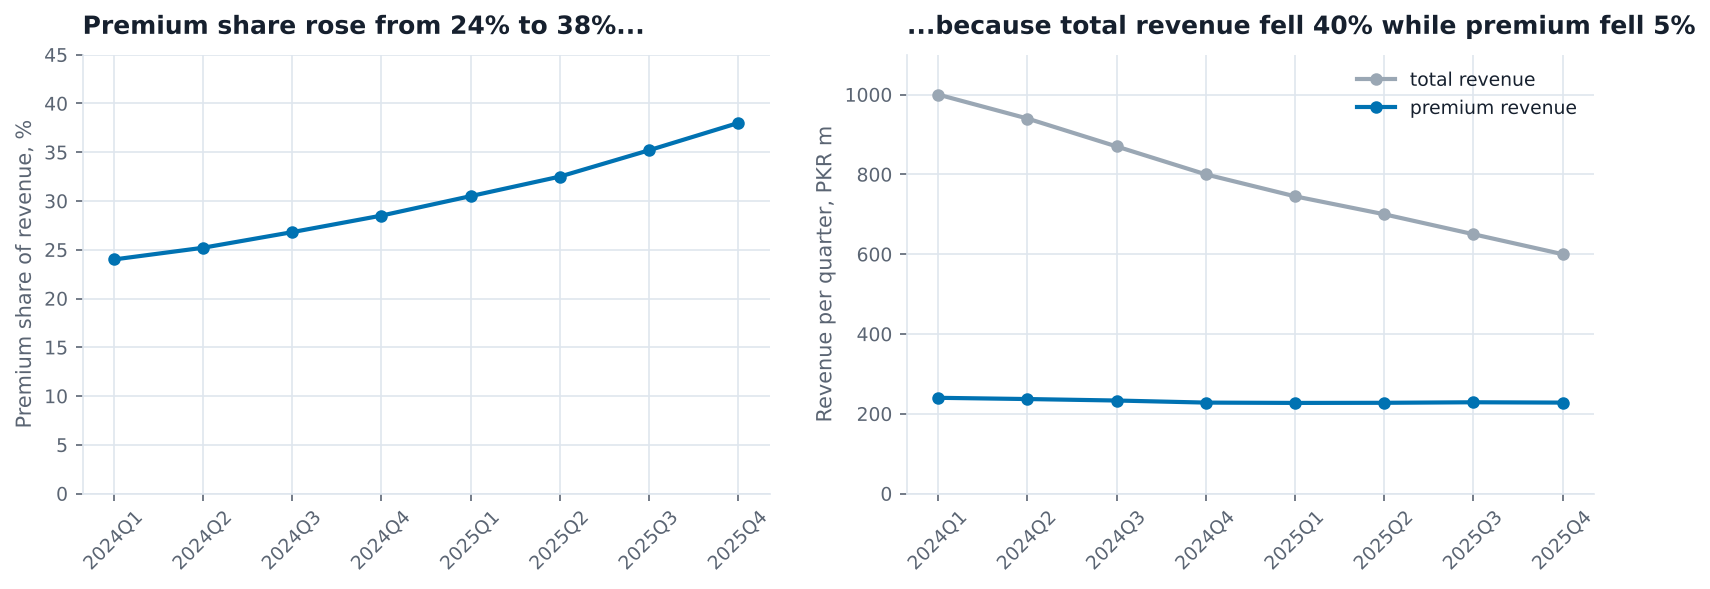

In [38]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(13, 3.8))

ax1.plot(c9["quarter"], c9["share"], marker="o", color=blue)
ax1.set_ylim(0, 45)
ax1.set_ylabel("Premium share of revenue, %")
ax1.set_title("Premium share rose from 24% to 38%...")

ax2.plot(c9["quarter"], c9["total_revenue_pkr_m"], marker="o", color=grey, label="total revenue")
ax2.plot(c9["quarter"], c9["premium_revenue_pkr_m"], marker="o", color=blue, label="premium revenue")
ax2.set_ylim(0, 1100)
ax2.set_ylabel("Revenue per quarter, PKR m")
ax2.set_title("...because total revenue fell 40% while premium fell 5%")
ax2.legend()

for ax in (ax1, ax2):
    ax.tick_params(axis="x", rotation=45)

fig.savefig(OUT + "A9_redesign.png", dpi=300, bbox_inches="tight")
plt.show()

---
# Part D (step 1) · Clean `sessions_hourly.csv`

Part B uses the cleaned daily series, so the cleaning comes first. The brief says to run these four calls, in this order.

In [39]:
df = pd.read_csv(DATA + "sessions_hourly.csv")
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 12670 entries, 0 to 12669
Data columns (total 5 columns):
 #   Column       Non-Null Count  Dtype
---  ------       --------------  -----
 0   ts           12670 non-null  str  
 1   sessions     12670 non-null  int64
 2   orders       12670 non-null  int64
 3   revenue_pkr  12670 non-null  int64
 4   device       12670 non-null  str  
dtypes: int64(3), str(2)
memory usage: 495.1 KB


In [40]:
df.describe().T

,count,mean,std,min,25%,50%,75%,max
sessions,12670.0,947.951381,646.882994,-1.0,435.0,756.0,1368.00,9811.0
orders,12670.0,30.016732,20.089492,4.0,14.0,24.0,42.00,304.0
revenue_pkr,12670.0,132564.968824,100150.706234,10350.0,58036.5,102359.0,182232.25,1652881.0


In [41]:
df["device"].value_counts()

device
Mobile     6994
Desktop    3452
mobile      883
Tablet      777
desktop     318
MOBILE      246
Name: count, dtype: int64

In [42]:
df["ts"].head(10).tolist()

['2024-04-29 11:00:00',
 '2024-10-26 05:00:00',
 '2025-08-04 20:00:00',
 '2024-10-05 19:00:00',
 '2025-01-22 20:00:00',
 '05/10/2024 09:00',
 '2024-08-11 15:00:00',
 '12/04/2025 10:00',
 '2024-07-24 02:00:00',
 '2025-03-27 11:00:00']

What I see in those four outputs:

1. `ts` is **text**, not a datetime (`df.info()`).
2. `sessions` has a minimum of **−1** — a sentinel, not a real count (`describe()`).
3. `device` has the same classes in **different cases**: `Mobile` / `mobile` / `MOBILE`, `Desktop` / `desktop`.
4. `ts` is written in **two formats** (`2024-04-29 11:00:00` and `05/10/2024 09:00`) and the rows are **not in time order**.

### Fault 1 — two timestamp formats

In [43]:
iso = df["ts"].str.match(r"^\d{4}-")
print("YYYY-MM-DD rows:", iso.sum(), "   dd/mm/yyyy rows:", (~iso).sum())

other = df.loc[~iso, "ts"]
first_num = other.str[:2].astype(int)
second_num = other.str[3:5].astype(int)
print("slash rows where the 1st number > 12:", (first_num > 12).sum())
print("slash rows where the 2nd number > 12:", (second_num > 12).sum())

YYYY-MM-DD rows: 9019    dd/mm/yyyy rows: 3651
slash rows where the 1st number > 12: 2151
slash rows where the 2nd number > 12: 0


In the slash rows the first number goes above 12 in many rows but the second never does, so the format is **day/month/year**.

The trap: `format="mixed"` parses every row with no error. Let's see what it does.

In [44]:
mixed = pd.to_datetime(df["ts"], format="mixed")
print("format='mixed' range:", mixed.min(), "to", mixed.max())

part1 = pd.to_datetime(df["ts"].where(iso), format="%Y-%m-%d %H:%M:%S")
part2 = pd.to_datetime(df["ts"].where(~iso), format="%d/%m/%Y %H:%M")
df["time"] = part1.fillna(part2)

print("my parse range:      ", df["time"].min(), "to", df["time"].max())
print("rows not parsed:", df["time"].isna().sum())
print("rows that 'mixed' put on a different date:", (mixed != df["time"]).sum())

format='mixed' range: 2024-01-04 01:00:00 to 2025-12-08 22:00:00
my parse range:       2024-04-01 00:00:00 to 2025-09-11 23:00:00
rows not parsed: 0
rows that 'mixed' put on a different date: 1382


`format="mixed"` reads `05/10/2024` as **May 10** (month first), so it moves **1,382 rows** to the wrong date and stretches the data to Jan 2024 – Dec 2025. The data dictionary says the data starts in **April 2024**, and my explicit two-format parse gives exactly **1 April 2024 → 11 September 2025**.

### Fault 2 — device labels

In [45]:
df["device"] = df["device"].str.strip().str.title()
df["device"].value_counts()

device
Mobile     8123
Desktop    3770
Tablet      777
Name: count, dtype: int64

### Faults 3 & 4 — unsorted index and duplicate hours

These only show up once the index is a real `DatetimeIndex`.

In [46]:
df = df.set_index("time")
print("sorted before sort_index?", df.index.is_monotonic_increasing)
df = df.sort_index()

audit_hourly = tslib.audit_index(df, "h")
audit_hourly

sorted before sort_index? False


{'dtype_ok': True,
 'monotonic': True,
 'n_rows': 12670,
 'n_duplicated': 286,
 'n_missing': 312,
 'missing_dates': ['2024-05-18 00:00:00',
  '2024-05-18 01:00:00',
  '2024-05-18 02:00:00',
  '2024-05-18 03:00:00',
  '2024-05-18 04:00:00',
  '2024-05-18 05:00:00',
  '2024-05-18 06:00:00',
  '2024-05-18 07:00:00',
  '2024-05-18 08:00:00',
  '2024-05-18 09:00:00',
  '2024-05-18 10:00:00',
  '2024-05-18 11:00:00'],
 'span': ('2024-04-01 00:00:00', '2025-09-11 23:00:00'),
 'partial_tail': False,
 'tail_period': '2025-09-11',
 'tail_count': 24}

In [47]:
dupes = df[df.index.duplicated(keep=False)]
same = dupes.drop(columns="ts").reset_index().duplicated(keep=False).sum()
print("rows sharing a timestamp:", len(dupes), "  of those, identical in every value:", same)

rows_before = len(df)
df = df[~df.index.duplicated(keep="first")]
print("duplicates removed:", rows_before - len(df), "  rows:", rows_before, "->", len(df))

rows sharing a timestamp: 572   of those, identical in every value: 572
duplicates removed: 286   rows: 12670 -> 12384


All 572 rows that share a timestamp are exact copies (often the same hour written once in each format), so I keep the first copy of each: **286 rows removed**.

### Fault 5 — the −1 sentinel

In [48]:
bad = df["sessions"] < 0
print("hours with sessions = -1:", bad.sum())
print("orders in those hours (min, max):", df.loc[bad, "orders"].min(), df.loc[bad, "orders"].max())

df["sessions"] = df["sessions"].where(~bad)
print("sessions missing now:", df["sessions"].isna().sum())

hours with sessions = -1: 287
orders in those hours (min, max): 5 83
sessions missing now: 287


Those hours still have orders (5 to 83), so the hour was real; only the sessions counter failed. I set those 287 values to `NaN` instead of deleting the row.

### Fault 6 — whole days never recorded

In [49]:
audit_clean = tslib.audit_index(df, "h")
print("missing hours:", audit_clean["n_missing"])

rows_per_day = df["sessions"].resample("D").size()
print("rows per day:", rows_per_day.value_counts().to_dict())
missing_days = rows_per_day[rows_per_day == 0].index
print("days with no data at all:", len(missing_days))
print([d.strftime("%Y-%m-%d") for d in missing_days])

missing hours: 312
rows per day: {24: 516, 0: 13}
days with no data at all: 13
['2024-05-18', '2024-07-02', '2024-07-03', '2024-09-27', '2024-11-11', '2024-12-25', '2025-01-01', '2025-02-14', '2025-03-30', '2025-03-31', '2025-06-07', '2025-07-19', '2025-08-23']


**312 missing hours = 13 complete days** (every recorded day has all 24 rows; the missing ones have none). The dictionary says there is no daylight saving, so these are collector outages. I keep them as `NaN` so the line breaks — I do not fill them.

### The partial final month

In [50]:
print("last timestamp:", df.index.max())
print("rows in September 2025:", len(df.loc["2025-09"]), "(a full month would be 720)")

last timestamp: 2025-09-11 23:00:00
rows in September 2025: 264 (a full month would be 720)


The extract stops on **11 September 2025**, so September is a partial month. I cut the series at **31 August 2025** so every month in it is complete (17 full months, April 2024 – August 2025).

### Build the daily series

Sessions are a **flow**, so daily = sum of the hours. To stop the sentinel hours from pulling a day down, my rule is: **daily sessions = mean of the valid hours × 24**. A day with no valid hour stays `NaN`.

In [51]:
hourly = df.loc[:"2025-08-31", "sessions"]

daily = hourly.resample("D").mean() * 24
plain_sum = hourly.resample("D").sum(min_count=1)

print("days:", len(daily), "  NaN days (outages):", daily.isna().sum())
print("days with 1-3 sentinel hours:", ((hourly.resample("D").count() < 24) & (hourly.resample("D").count() > 0)).sum())
print("Black Friday 2024-11-29:", daily["2024-11-29"])
print("median daily sessions, plain sum vs my rule:", plain_sum.median(), "vs", round(daily.median()))
print(tslib.audit_index(daily, "D"))

days: 518   NaN days (outages): 13
days with 1-3 sentinel hours: 215
Black Friday 2024-11-29: 113710.0
median daily sessions, plain sum vs my rule: 22068.0 vs 22627
{'dtype_ok': True, 'monotonic': True, 'n_rows': 518, 'n_duplicated': 0, 'n_missing': 0, 'missing_dates': [], 'span': ('2024-04-01 00:00:00', '2025-08-31 00:00:00'), 'partial_tail': False, 'tail_period': '2025-08', 'tail_count': 31}


---
# Part B · Smoothing, windows and panel shape — computed

### B1 · The window is a hypothesis

In [52]:
report = tslib.window_report(daily, windows=(7, 28, 91))
report

,window,raw_sd,smoothed_sd,variation_removed_pct,periods_lost_each_end
0,7,6818.197,4646.1871,31.9,3
1,28,6818.197,4430.7976,35.0,14
2,91,6818.197,4152.4932,39.1,45


| Window | Cycle it removes | Raw variation removed | Days lost each end |
|---|---|---|---|
| 7 days | the **weekly** cycle (weekend high, weekday low) — one full week averages it out exactly | 31.9% | 3 |
| 28 days | the weekly cycle (4 full weeks) plus month-scale noise like the Black Friday week | 35.0% | 14 |
| 91 days | weeks, months, and even part of the **seasonal turn** itself (a quarter) | 39.1% | 45 |

Only 32–39% of the variation goes, because most of the variation in this series is the slow trend, which none of these windows should remove.

**My choice for Part D: 7 days (centred).** The cycle that hides the trend is weekly, and 7 days is exactly one week, so every window has each weekday once. 28 removes the same weekly cycle but also flattens the November peak and loses 2 weeks at each end; 91 would start eating the seasonal turn — the very thing leadership keeps missing.

### B2 · Three smoothers against one spike

In [53]:
bf = "2024-11-29"
mean14 = daily.rolling(14, center=True, min_periods=7).mean()
median14 = daily.rolling(14, center=True, min_periods=7).median()
ewma14 = daily.ewm(span=14).mean()

print("raw on Black Friday:      ", round(daily[bf]))
print("14-day centred mean:      ", round(mean14[bf]))
print("14-day centred median:    ", round(median14[bf]))
print("EWMA (span 14):           ", round(ewma14[bf]))
print("fortnight median (raw):   ", round(daily["2024-11-22":"2024-12-05"].median()))

raw on Black Friday:       113710
14-day centred mean:       33382
14-day centred median:     24780
EWMA (span 14):            38229
fortnight median (raw):    24780


- **Mean:** ~33,400 — one day of 113,710 drags the whole 14-day average up by about a third.
- **Median:** ~24,800 — basically ignores the spike (the brief's fortnight median is about 24,600).
- **EWMA:** ~38,200 — the highest, because it weights the most recent day the most.

**Monitoring dashboard → EWMA.** It only uses past data (so it can be computed every morning) and reacts quickly to a sudden jump — on a monitoring screen you *want* to see Black Friday or an outage.
**Quarterly report → centred median.** A quarterly report is about the underlying level; the median is not pulled by one-day events, and centring puts the turn on the right date.

### B3 · Decompose it

`seasonal_decompose` cannot handle `NaN`, so for this step only I fill the 13 outage days by linear interpolation (marked: these filled days are **not** used in any figure).

In [54]:
filled = daily.interpolate()
print("days filled for decomposition only:", daily.isna().sum())

dec7 = seasonal_decompose(filled, model="additive", period=7)
seasonal = dec7.seasonal
print("weekly seasonal amplitude (peak - trough):", round(seasonal.max() - seasonal.min()))
print(seasonal.groupby(seasonal.index.day_name()).mean().round(0).sort_values())

print("\nlargest residual:", dec7.resid.abs().idxmax().date(), " value:", round(dec7.resid[dec7.resid.abs().idxmax()]))
print(dec7.resid.abs().sort_values(ascending=False).head(5).round(0))

days filled for decomposition only: 13
weekly seasonal amplitude (peak - trough): 7569
time
Thursday    -2378.0
Wednesday   -2330.0
Tuesday     -2274.0
Monday      -2163.0
Friday       -947.0
Saturday     4902.0
Sunday       5191.0
Name: seasonal, dtype: float64

largest residual: 2024-11-29  value: 74659
time
2024-11-29    74659.0
2024-12-02    13047.0
2024-11-26    13001.0
2024-11-27    12642.0
2024-11-30    12446.0
Name: resid, dtype: float64


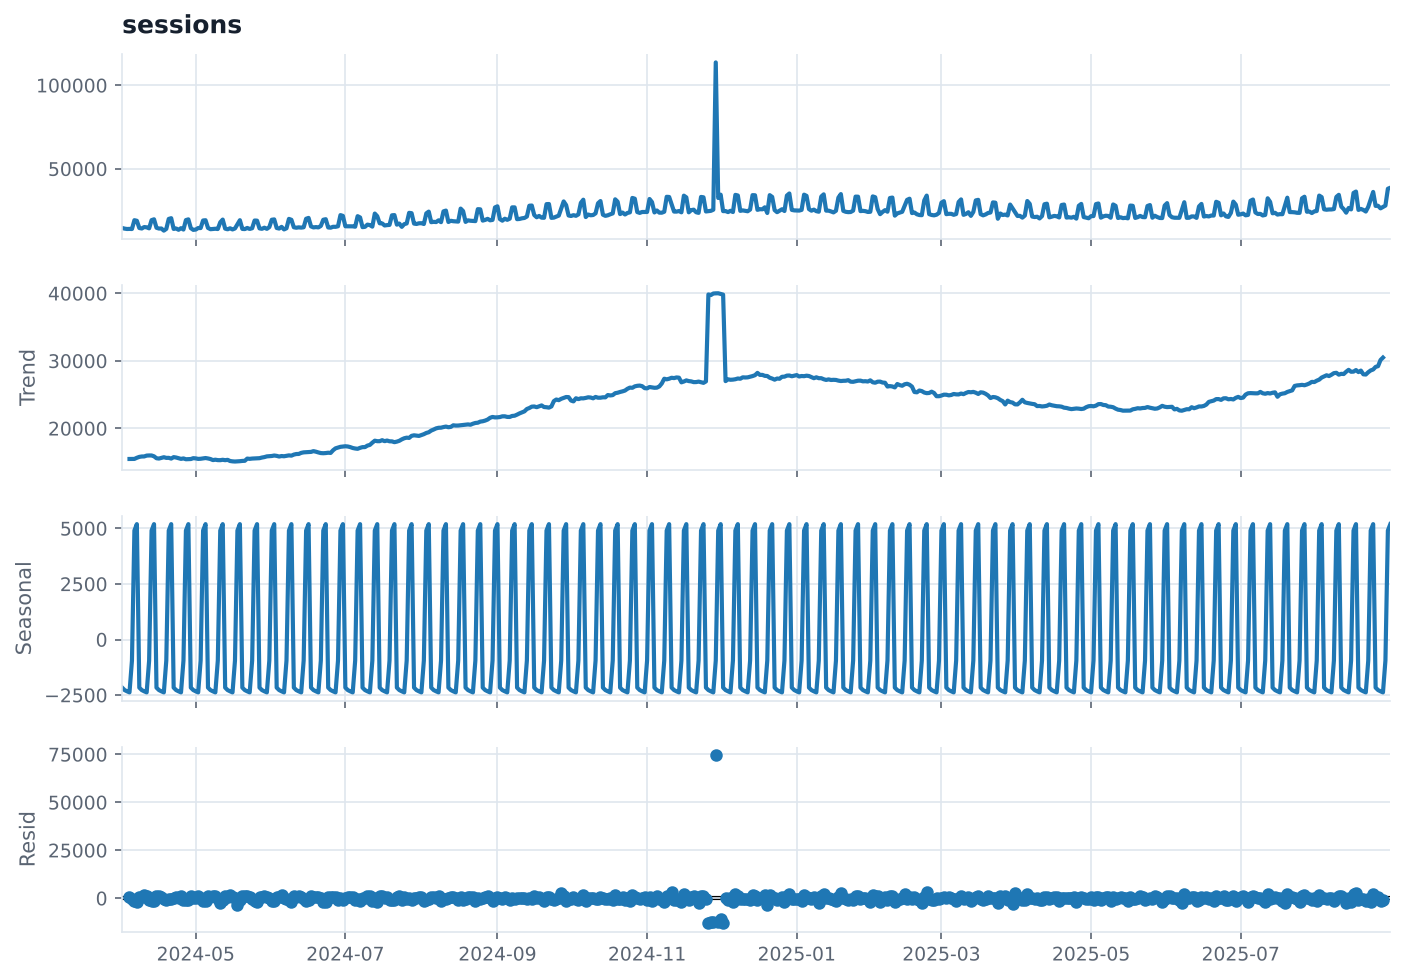

In [55]:
fig = dec7.plot()
fig.set_size_inches(10, 7)
fig.savefig(OUT + "B3_decompose.png", dpi=300, bbox_inches="tight")
plt.show()

In [56]:
try:
    dec365 = seasonal_decompose(filled, model="additive", period=365)
except ValueError as e:
    print("period=365 failed:", e)

period=365 failed: x must have 2 complete cycles requires 730 observations. x only has 518 observation(s)


- The weekly seasonal component swings about **7,600 sessions/day** from trough (Thursday, about −2,400) to peak (Sunday, about +5,200).
- The largest residual is **2024-11-29 — Black Friday** (about +74,700). After trend and the weekly pattern are removed, that one event is what's left, which is the point.
- `period=365` **does not run**: statsmodels needs two full cycles (730 days) and we only have 518. If we had two years, the **yearly** pattern (the November peak and the spring dip, and a repeating Black Friday) would move out of `resid` (and out of `trend`) into `seasonal`.

### B4 · Trailing or centred

In [57]:
lag31 = tslib.lag_at_turn(filled, 31, how="max")
print(lag31)

{'window': 31, 'trailing_turn': Timestamp('2024-12-29 00:00:00'), 'centred_turn': Timestamp('2024-12-14 00:00:00'), 'lag_periods': 15, 'half_window': 15}


I use the **peak** (`how="max"`) because the seasonal turn leadership is missing is the late-2024 top. The centred 31-day mean peaks on **2024-12-14** and the trailing one on **2024-12-29**: a lag of **15 days**, exactly the half-window (31 // 2 = 15).

**A live dashboard refreshed every morning must show the trailing mean**, because a centred mean needs 15 future days that don't exist yet (the last 15 points would be blank). The caption must say: *"31-day trailing mean — turning points appear about 15 days after they happen."*

### B5 · The window is a claim

For each of 12 start months (April 2024 – March 2025) and each window length of 7, 14, 28, 56, 91 days, I take that slice of the daily series, fit a straight line, and check the sign of the slope.

In [58]:
starts = pd.date_range("2024-04-01", periods=12, freq="MS")
lengths = [7, 14, 28, 56, 91]

results = []
for start in starts:
    for n_days in lengths:
        piece = daily[start : start + pd.Timedelta(days=n_days - 1)].dropna()
        x = (piece.index - piece.index[0]).days
        slope = np.polyfit(x, piece.values, 1)[0]
        results.append({"start": start.strftime("%Y-%m"), "days": n_days, "slope": round(slope, 1)})

results = pd.DataFrame(results)
results["direction"] = np.where(results["slope"] > 0, "rising", "falling")

print(results["direction"].value_counts())
results.pivot(index="start", columns="days", values="direction")

direction
rising     34
falling    26
Name: count, dtype: int64


days,7,14,28,56,91
start,,,,,
2024-04,rising,rising,rising,rising,rising
2024-05,rising,rising,rising,rising,rising
2024-06,falling,falling,falling,rising,rising
2024-07,rising,rising,rising,rising,rising
2024-08,falling,rising,rising,rising,rising
2024-09,falling,rising,rising,rising,rising
2024-10,rising,rising,rising,rising,rising
2024-11,falling,falling,falling,rising,falling
2024-12,falling,rising,rising,falling,falling


Out of 60 combinations, **34 show a rising trend and 26 a falling one** — from the same unchanged series.

**Why the Lie Factor can't be computed here:** Lie Factor = (effect shown) / (effect in the data). The formula assumes there is **one true "effect in the data"** to divide by. But the effect depends on the window you pick: there is no single trend for "the data" — each start/length gives a different one, and some even have the opposite sign. A cherry-picked window doesn't distort a true number; it *chooses* which number becomes the truth, so there's no honest denominator.

**Honest substitute:** fix the window *before* looking (from the cycle you want to remove), show the full series from its first recorded day, and report the **spread** — e.g. "34 of 60 start/length combinations rise, 26 fall" — so the reader knows how fragile the direction is.

---
# Part C · Part-to-whole legality, and the ranking

### C1 · The three conditions, tested in code

In [59]:
print("1) case08 touch_* columns")
print(tslib.exclusivity_check(c8, touch))

1) case08 touch_* columns
{'n': 4000, 'shares_pct': {'touch_search': 42.62, 'touch_social': 32.3, 'touch_email': 27.48, 'touch_direct': 28.58}, 'sum_pct': 130.98, 'exclusive': False, 'n_multi': 1105, 'pct_multi': 27.62, 'n_zero': 0}


In [60]:
s8 = pd.read_csv(DATA + "shares_eight.csv")
print("2) shares_eight.csv")
print("sum:", s8["share_pct"].sum())
assert abs(s8["share_pct"].sum() - 100) < 1e-6
print("each sub-category once?", s8["subcategory"].is_unique)

catalogue_raw = pd.read_csv(DATA + "revenue_catalogue.csv")
print("sub-categories in the catalogue:", catalogue_raw["subcategory"].nunique())

2) shares_eight.csv
sum: 100.0
each sub-category once? True
sub-categories in the catalogue: 8


In [61]:
q4 = c9[c9["quarter"] == "2025Q4"].iloc[0]
premium = q4["premium_revenue_pkr_m"]
other_rev = q4["total_revenue_pkr_m"] - premium
two = pd.Series({"premium": premium, "other": other_rev}) / q4["total_revenue_pkr_m"] * 100
print("3) 2025Q4 premium vs other")
print(two.round(1))
assert abs(two.sum() - 100) < 1e-6

3) 2025Q4 premium vs other
premium    38.0
other      62.0
dtype: float64


| Table | Exclusive parts? | Meaningful whole? | Is share the question? | Verdict |
|---|---|---|---|---|
| case08 `touch_*` | **No** — 1,105 customers in 2+ channels, sum = 131% | No — "customers" counted up to 4 times is not a whole | No — the question is reach | **Neither a pie nor a stacked bar.** Separate bars of reach (each out of 100%) are fine |
| `shares_eight.csv` | Yes — 8 different sub-categories, sums to exactly 100 | Yes — the 8 are *all* the sub-categories of the catalogue, so the whole is total net revenue | Yes — "what share does each sub-category have" | **A pie is legal, but bars are better**: 8 slices, and C/H/G are within 4 points of each other, which angle can't separate |
| 2025Q4 premium vs other | Yes — other = total − premium, sums to 100 | Yes — total revenue that quarter | **No** — the claim is about premium *growing*, and a share of one quarter can't show that | **A 2-slice pie is legal but answers the wrong question.** Draw the absolute revenue over time (Case 9 redesign) |

### C2 · The ranking experiment

The stimuli: a pie with **no numbers**, in file order, `startangle=90, counterclock=False`, and the same eight as sorted horizontal bars with no numbers. All slices/bars use one colour so colour gives no hint.

In [62]:
def draw_pie():
    fig, ax = plt.subplots(figsize=(5, 5))
    ax.pie(s8["share_pct"], labels=s8["slice"], startangle=90, counterclock=False,
           colors=[blue] * 8, wedgeprops={"edgecolor": "white", "linewidth": 1.5},
           textprops={"fontsize": 13})
    ax.set_title("Rank the slices A-H, largest first")
    return fig


def draw_bars():
    sorted8 = s8.sort_values("share_pct")
    fig, ax = plt.subplots(figsize=(6, 4))
    ax.barh(sorted8["slice"], sorted8["share_pct"], color=blue)
    ax.set_xticks([])
    ax.grid(False)
    ax.spines["bottom"].set_visible(False)
    ax.set_title("Rank the bars A-H, largest first")
    return fig


fig = draw_pie()
fig.savefig(OUT + "stimulus_pie.png", dpi=300, bbox_inches="tight")
plt.close(fig)

fig = draw_bars()
fig.savefig(OUT + "stimulus_bars.png", dpi=300, bbox_inches="tight")
plt.close(fig)

print("saved outputs/stimulus_pie.png and outputs/stimulus_bars.png")

saved outputs/stimulus_pie.png and outputs/stimulus_bars.png


**Run the next two cells with a real reader** (a friend or class fellow who has not seen the numbers). Each cell shows the chart, starts the clock, and waits for the reader to type the letters in order (e.g. `ACBHGDEF`). Timing uses `time.perf_counter()`.

In [ ]:
reader = input("Reader's name: ")

fig = draw_pie()
plt.show()

start = time.perf_counter()
pie_order = input("PIE — type the letters largest first: ")
pie_seconds = time.perf_counter() - start

pie_order = pie_order.upper().replace(" ", "").replace(",", "")
print("pie:", pie_order, " time:", round(pie_seconds, 1), "s")

In [ ]:
fig = draw_bars()
plt.show()

start = time.perf_counter()
bar_order = input("BARS — type the letters largest first: ")
bar_seconds = time.perf_counter() - start

bar_order = bar_order.upper().replace(" ", "").replace(",", "")
print("bars:", bar_order, " time:", round(bar_seconds, 1), "s")

answers = pd.DataFrame({
    "reader": [reader, reader],
    "stimulus": ["pie", "bars"],
    "order": [pie_order, bar_order],
    "seconds": [round(pie_seconds, 2), round(bar_seconds, 2)],
})
answers.to_csv(OUT + "pie_ranking_results.csv", index=False)
answers

### C3 · Score it

In [65]:
true_order = "".join(s8.sort_values("share_pct", ascending=False)["slice"])
print("true order:", true_order)
print(s8.sort_values("share_pct", ascending=False).to_string(index=False))

if os.path.exists(OUT + "pie_ranking_results.csv"):
    answers = pd.read_csv(OUT + "pie_ranking_results.csv")
    for _, row in answers.iterrows():
        given = str(row["order"])
        wrong = [i + 1 for i in range(8) if i >= len(given) or given[i] != true_order[i]]
        print(f"\n{row['stimulus']}: {given}  ({row['seconds']} s)")
        print("  letters in the wrong place:", len(wrong))
        print("  wrong rank positions:", wrong)
else:
    print("\nNo results yet — run the two experiment cells above first.")

true order: ABCHGDEF
slice subcategory  share_pct
    A      Phones       24.6
    B     Laptops       18.4
    C       Audio       15.0
    H Accessories       13.1
    G    Footwear       11.2
    D   Wearables        9.2
    E     Cameras        6.1
    F      Drones        2.4

No results yet — run the two experiment cells above first.


**My result (fill in after running the experiment):**

- Reader: ______ (one person).
- Pie: ___ letters in the wrong place, at rank positions ___; took ___ s.
- Bars: ___ letters in the wrong place; took ___ s.
- The deck predicts the top two (A, B) and the bottom one (F) are right, and the errors fall in the middle where **C (15.0%), H (13.1%) and G (11.2%)** are only about 2 points apart. In my test this **did / did not** happen: ______.

One reader is one reader. This shows what happened for this one person on one try; it can't say how often readers in general get it wrong, or that bars are faster for everyone. (Also, the bar chart came second and was already sorted, so it is partly a test of reading order, not just of the channel.)

### C4 · My rule

I will only draw a pie when the parts are exclusive and sum to a meaningful whole, the question really is "what share of the whole", and there are at most 3 slices that are clearly different in size — otherwise I use sorted bars.

---
# Part D (step 2) · The e-commerce review figure

### The catalogue — check the tree first

In [66]:
cat = pd.read_csv(DATA + "revenue_catalogue.csv")

print("parents per sub-category:", cat.groupby("subcategory")["category"].nunique().max())
print("duplicate SKUs:", cat["sku"].duplicated().sum())
print(cat[cat["sku"].duplicated(keep=False)][["sku", "sku_name", "category", "subcategory", "net_revenue_pkr_m"]])

parents per sub-category: 1
duplicate SKUs: 1
          sku sku_name         category subcategory  net_revenue_pkr_m
126  SKU-0127  AUDI-04  Audio & Imaging       Audio            14.8275
344  SKU-0127  AUDI-04        Lifestyle   Wearables            14.8275


`SKU-0127` appears twice: once under *Audio & Imaging → Audio* and once under *Lifestyle → Wearables*, with identical numbers. Its name is `AUDI-04`, an Audio name, so the Wearables row is the copy. One child can only have one parent in a tree, so I keep the first (Audio) row and drop the Wearables one.

In [67]:
rows_before = len(cat)
cat = cat.drop_duplicates(subset="sku", keep="first")
print("rows:", rows_before, "->", len(cat))

negative = cat[cat["net_revenue_pkr_m"] < 0]
print("\nSKUs with negative net revenue:", len(negative), "  total:", round(negative["net_revenue_pkr_m"].sum(), 2), "PKR m")
print(negative[["sku", "subcategory", "net_revenue_pkr_m"]])

positive = cat[cat["net_revenue_pkr_m"] >= 0]

rows: 345 -> 344

SKUs with negative net revenue: 7   total: -1.07 PKR m
          sku  subcategory  net_revenue_pkr_m
57   SKU-0058  Accessories            -0.0001
232  SKU-0233       Drones            -0.0617
241  SKU-0242       Drones            -0.0519
271  SKU-0272    Wearables            -0.0268
298  SKU-0299    Wearables            -0.3039
334  SKU-0335     Footwear            -0.1376
343  SKU-0344     Footwear            -0.4873


**7 SKUs** have net revenue below zero (returns bigger than sales), together **−1.07 PKR m**. Negatives have no area, so they are left out of the treemap and bars and **listed on the figure** instead.

In [68]:
sub = positive.groupby(["category", "subcategory"])["net_revenue_pkr_m"].sum().reset_index()
sub["share"] = sub["net_revenue_pkr_m"] / sub["net_revenue_pkr_m"].sum() * 100
sub = sub.sort_values("net_revenue_pkr_m", ascending=False)

check = sub.set_index("subcategory")["share"].round(2).to_frame("mine")
check["shares_eight"] = s8.set_index("subcategory")["share_pct"]
check["diff"] = (check["mine"] - check["shares_eight"]).round(2)
print(check)
print("largest difference:", check["diff"].abs().max(), "points")
assert check["diff"].abs().max() < 0.3
assert abs(sub["share"].sum() - 100) < 1e-6

              mine  shares_eight  diff
subcategory                           
Phones       24.75          24.6  0.15
Laptops      18.22          18.4 -0.18
Audio        14.98          15.0 -0.02
Accessories  13.33          13.1  0.23
Footwear     10.99          11.2 -0.21
Wearables     9.36           9.2  0.16
Cameras       5.97           6.1 -0.13
Drones        2.41           2.4  0.01
largest difference: 0.23 points


Self-check passes: all eight shares are within **0.3 points** of `shares_eight.csv` (the biggest gap is 0.23). Before removing the duplicate SKU, Wearables was 10.13% vs 9.2% — out by ~0.9, exactly the warning in the brief.

**Other bucket for the treemap.** 8 blocks is more than the 4 ± 1 chunks a reader holds, so in the treemap I fold sub-categories under 7% into `Other`. The bars in panel 4 still show all 8, so nothing is hidden.

In [69]:
by_sub = sub.set_index("subcategory")["net_revenue_pkr_m"]
tree_values, other_note = tslib.rollup_other(by_sub, min_share_pct=7)
print(tree_values.round(1))
print(other_note)

Phones         423.8
Laptops        312.0
Audio          256.5
Accessories    228.2
Footwear       188.1
Wearables      160.3
Other          143.5
dtype: float64
Other = 2 categories below 7% of the total, 143.5 combined (8.4%)


Both rolled-up sub-categories (Cameras and Drones) belong to *Audio & Imaging*, so `Other` keeps that parent's colour.

### Heatmap data and the banked aspect ratio

In [70]:
heat = hourly.to_frame("sessions")
heat["weekday"] = heat.index.dayofweek
heat["hour"] = heat.index.hour
heat_table = heat.pivot_table(index="weekday", columns="hour", values="sessions", aggfunc="mean")

peak = heat_table.stack().idxmax()
low = heat_table.stack().idxmin()
days_names = ["Mon", "Tue", "Wed", "Thu", "Fri", "Sat", "Sun"]
print("busiest cell:", days_names[peak[0]], peak[1], ":00 ->", round(heat_table.max().max()))
print("quietest cell:", days_names[low[0]], low[1], ":00 ->", round(heat_table.min().min()))
print("mean per hour by weekday:", heat_table.mean(axis=1).round(0).tolist())

busiest cell: Sun 20 :00 -> 2326
quietest cell: Wed 4 :00 -> 363
mean per hour by weekday: [862.0, 868.0, 864.0, 867.0, 920.0, 1180.0, 1187.0]


In [71]:
smooth7 = daily.rolling(7, center=True, min_periods=5).mean()
banked = tslib.banked_figsize(smooth7.values, width=7.5)
print("banked size for panel 1:", tuple(round(v, 2) for v in banked), " aspect (h/w):", round(banked[1] / banked[0], 2))

print("monthly mean of daily sessions:")
print(daily.resample("MS").mean().round(0))

banked size for panel 1: (7.5, 3.77)  aspect (h/w): 0.5
monthly mean of daily sessions:
time
2024-04-01    15544.0
2024-05-01    15252.0
2024-06-01    16638.0
2024-07-01    17932.0
2024-08-01    20440.0
2024-09-01    22961.0
2024-10-01    24882.0
2024-11-01    29991.0
2024-12-01    27707.0
2025-01-01    27079.0
2025-02-01    26016.0
2025-03-01    25035.0
2025-04-01    23142.0
2025-05-01    23087.0
2025-06-01    23653.0
2025-07-01    25253.0
2025-08-01    28847.0
Freq: MS, Name: sessions, dtype: float64


### The 2×2 figure

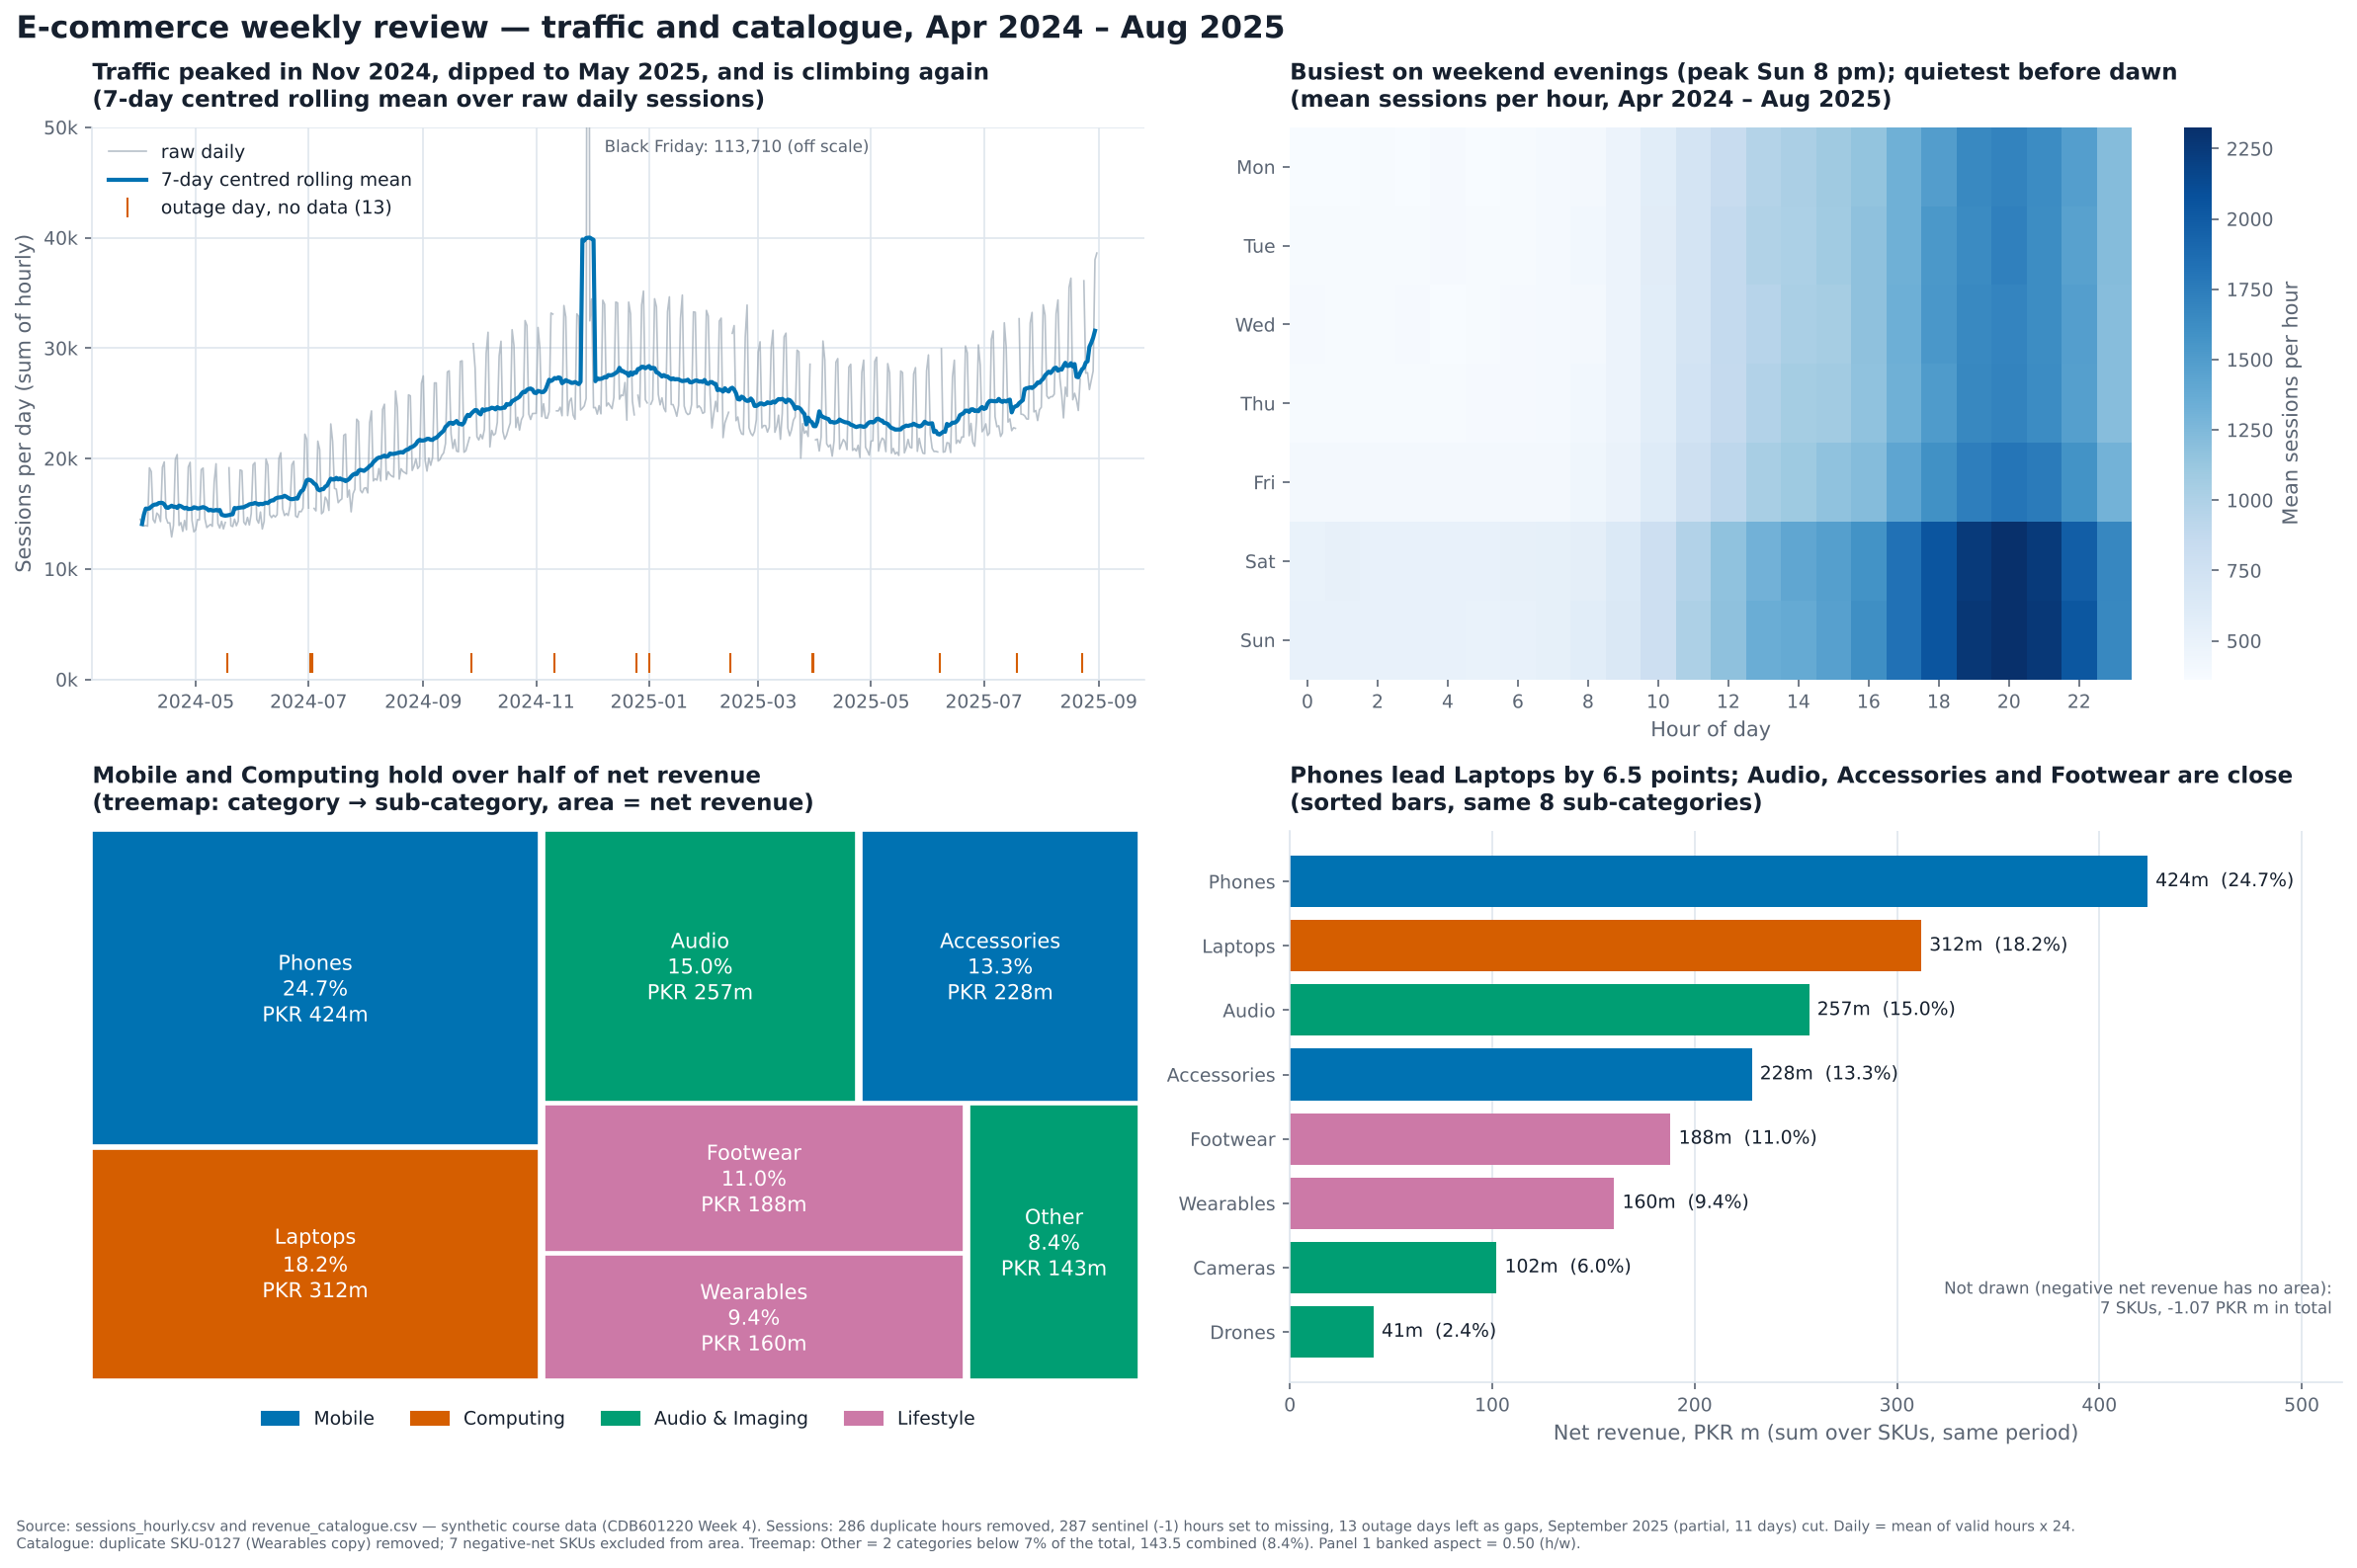

In [72]:
parent_colour = {"Mobile": blue, "Computing": orange, "Audio & Imaging": green, "Lifestyle": pink}
parent_of = dict(zip(sub["subcategory"], sub["category"]))
parent_of["Other"] = "Audio & Imaging"

fig, axes = plt.subplots(2, 2, figsize=(16, 10))
ax1, ax2, ax3, ax4 = axes[0, 0], axes[0, 1], axes[1, 0], axes[1, 1]

# panel 1
ax1.plot(daily.index, daily.values, color=grey, linewidth=0.8, alpha=0.7, label="raw daily")
ax1.plot(smooth7.index, smooth7.values, color=blue, linewidth=2, label="7-day centred rolling mean")
ax1.annotate("Black Friday: 113,710 (off scale)", ("2024-11-29", 50000), xytext=(8, -12), textcoords="offset points",
             fontsize=8, color=PALETTE["ink_soft"])
ax1.plot(missing_days, [1500] * len(missing_days), "|", color=orange, markersize=10, label="outage day, no data (13)")
ax1.set_ylim(0, 50000)
ax1.set_title("Traffic peaked in Nov 2024, dipped to May 2025, and is climbing again\n(7-day centred rolling mean over raw daily sessions)", fontsize=11)
ax1.set_ylabel("Sessions per day (sum of hourly)")
ax1.legend(loc="upper left")
ax1.yaxis.set_major_formatter(plt.FuncFormatter(lambda v, p: f"{v/1000:.0f}k"))

# panel 2
im = ax2.imshow(heat_table.values, aspect="auto", cmap=PALETTE["sequential"])
ax2.set_yticks(range(7))
ax2.set_yticklabels(days_names)
ax2.set_xticks(range(0, 24, 2))
ax2.set_xlabel("Hour of day")
ax2.grid(False)
ax2.set_title("Busiest on weekend evenings (peak Sun 8 pm); quietest before dawn\n(mean sessions per hour, Apr 2024 – Aug 2025)", fontsize=11)
bar = fig.colorbar(im, ax=ax2)
bar.set_label("Mean sessions per hour")
bar.outline.set_visible(False)
for side in ["left", "bottom"]:
    ax2.spines[side].set_visible(False)

# panel 3
tree_share = tree_values / tree_values.sum() * 100
tree_labels = [f"{name}\n{s:.1f}%" for name, s in zip(tree_values.index, tree_share)]
tree_colours = [parent_colour[parent_of[name]] for name in tree_values.index]
tslib.treemap(ax3, tree_values.values, labels=tree_labels, values=tree_values.values,
              colors=tree_colours, fontsize=10, value_fmt="PKR {:,.0f}m")
ax3.set_title("Mobile and Computing hold over half of net revenue\n(treemap: category → sub-category, area = net revenue)", fontsize=11)
handles = [plt.Rectangle((0, 0), 1, 1, color=c) for c in parent_colour.values()]
ax3.legend(handles, parent_colour.keys(), loc="upper center", bbox_to_anchor=(0.5, -0.02), ncol=4)

# panel 4
bars_data = sub.sort_values("net_revenue_pkr_m")
bar_colours = [parent_colour[c] for c in bars_data["category"]]
ax4.barh(bars_data["subcategory"], bars_data["net_revenue_pkr_m"], color=bar_colours)
for i, (v, s) in enumerate(zip(bars_data["net_revenue_pkr_m"], bars_data["share"])):
    ax4.text(v + 4, i, f"{v:,.0f}m  ({s:.1f}%)", va="center", fontsize=9)
ax4.set_xlim(0, 520)
ax4.set_xlabel("Net revenue, PKR m (sum over SKUs, same period)")
ax4.set_title("Phones lead Laptops by 6.5 points; Audio, Accessories and Footwear are close\n(sorted bars, same 8 sub-categories)", fontsize=11)
ax4.grid(axis="y", visible=False)
neg_text = "Not drawn (negative net revenue has no area):\n7 SKUs, -1.07 PKR m in total"
ax4.text(515, 0.2, neg_text, ha="right", va="bottom", fontsize=8, color=PALETTE["ink_soft"])

fig.suptitle("E-commerce weekly review — traffic and catalogue, Apr 2024 – Aug 2025", x=0.01, ha="left",
             fontsize=15, fontweight="bold")
fig.tight_layout()

note = ("Source: sessions_hourly.csv and revenue_catalogue.csv — synthetic course data (CDB601220 Week 4). "
        "Sessions: 286 duplicate hours removed, 287 sentinel (-1) hours set to missing, 13 outage days left as gaps, "
        "September 2025 (partial, 11 days) cut. Daily = mean of valid hours x 24.\n"
        "Catalogue: duplicate SKU-0127 (Wearables copy) removed; 7 negative-net SKUs excluded from area. "
        f"Treemap: {other_note}. Panel 1 banked aspect = {banked[1] / banked[0]:.2f} (h/w).")
save_fig(fig, OUT + "partD_figure.png", note=note)
plt.show()

### Appendix — the 28-day version

Declared in Part E: the 7-day window was fixed before plotting. This is the 28-day version, to check it does not change the direction.

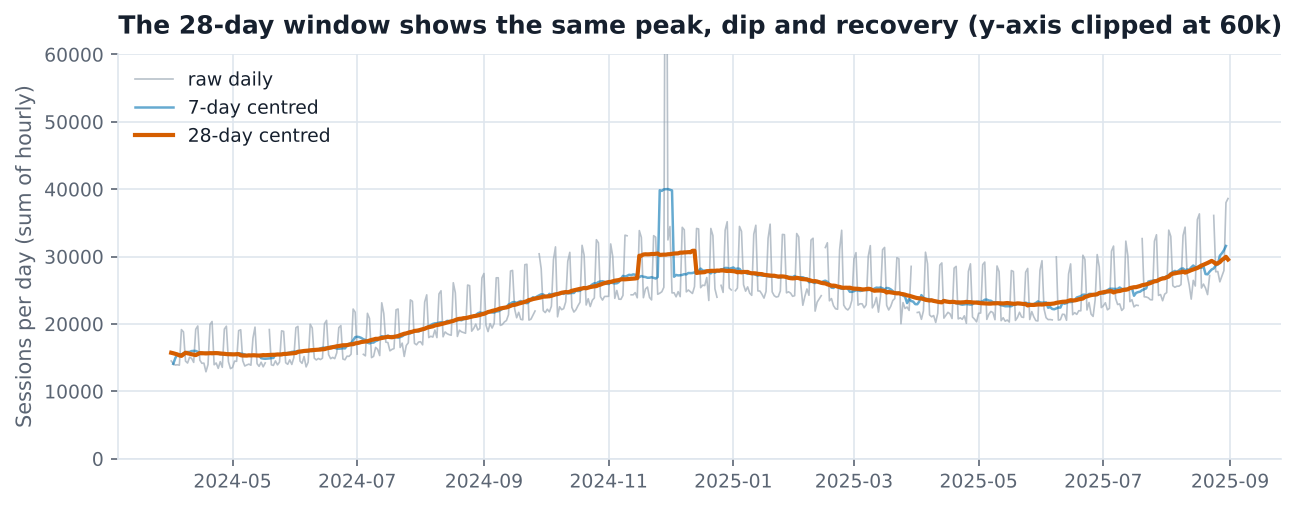

In [73]:
smooth28 = daily.rolling(28, center=True, min_periods=14).mean()

fig, ax = plt.subplots(figsize=(10, 3.5))
ax.plot(daily.index, daily.values, color=grey, linewidth=0.8, alpha=0.7, label="raw daily")
ax.plot(smooth7.index, smooth7.values, color=blue, linewidth=1.2, alpha=0.6, label="7-day centred")
ax.plot(smooth28.index, smooth28.values, color=orange, linewidth=2, label="28-day centred")
ax.set_ylim(0, 60000)
ax.set_title("The 28-day window shows the same peak, dip and recovery (y-axis clipped at 60k)")
ax.set_ylabel("Sessions per day (sum of hourly)")
ax.legend(loc="upper left")
fig.savefig(OUT + "partD_appendix_28day.png", dpi=300, bbox_inches="tight")
plt.show()

---
# Part E · Written justification

**1. Per panel**

- **Panel 1 — Is traffic going up or down, once the weekend rhythm is removed?** A line, because time is ordered and continuous. Position on a common scale (the best channel in the Week 2 ranking) carries the value. Raw in grey, the 7-day mean in the one pop-out colour (one pop-out per chart, grey for context).
- **Panel 2 — When in the week do people visit?** A day × hour heatmap. Colour lightness is a weaker channel, but the question is about the *pattern* across 168 cells, not exact values, and a single-hue sequential map (`Blues`) fits because sessions have no midpoint.
- **Panel 3 — Where is the revenue mass in the hierarchy?** A treemap, because it shows containment (sub-category inside category). Area is the 4th-best channel, so every block carries its % and PKR value in text, and one hue per parent category groups the blocks.
- **Panel 4 — By how much does each sub-category differ?** Sorted horizontal bars: length from a common zero baseline is read far more accurately than area, so this answers the "how much" that the treemap can't. Values are printed; colours match panel 3.

**2. Time decisions**

- **Parse:** `ts` had two formats. 9,019 rows are `YYYY-MM-DD HH:MM:SS`; 3,651 are `dd/mm/yyyy HH:MM`. I know the slash format is day-first because the first number goes above 12 and the second never does. I parsed each format explicitly. `format="mixed"` would have moved 1,382 rows to wrong dates (range Jan 2024 – Dec 2025 instead of 1 Apr 2024 – 11 Sep 2025).
- **Resolution:** daily for panel 1 (leadership reviews weekly, hourly is too noisy); hourly kept for the heatmap.
- **Aggregation:** sessions are a **flow**, so daily = sum of hours. To avoid sentinel hours pulling a day down, daily = mean of valid hours × 24 (215 days had 1–3 sentinel hours; the rule moves the median day from 22,068 with a plain sum to 22,627).
- **Window:** 7 days, because the cycle being removed is weekly (Part B1).
- **Centred, not trailing:** this is a review of the past, not a live monitor, so centring puts the turns on the right dates (a trailing 31-day mean put the peak 15 days late, Part B4). Cost: 3 days lost at each end.
- **Ethics clause:** the window was fixed at 7 days before plotting, because the cycle being removed is weekly (Part B1). The series is shown from its first recorded day (1 April 2024); no start date was selected. A 28-day version is in the appendix and does not change the direction. Symmetry test: I would have used 7 days even if it weakened the conclusion, because it was chosen from the weekly cycle, not from the look of the line — and Part B5 shows that 34 of 60 start/window combinations rise and 26 fall, so I report that rather than pick one.

**3. Rows removed or changed**

| Rule | Count | Effect |
|---|---|---|
| Exact duplicate hours (same timestamp, same values) — keep first | 286 rows | 12,670 → 12,384 rows |
| `sessions = -1` sentinel → `NaN` (row kept, orders were real) | 287 hours | describe() min went from −1 to a real count |
| 13 whole days never recorded — left as `NaN`, line breaks | 312 hours | not filled; interpolated **only** inside `seasonal_decompose` (Part B3) |
| September 2025 partial (11 days) — cut | 264 hours | series ends 31 Aug 2025: 518 days, 505 with data |
| Device labels lower/upper case → title case | 1,447 rows relabelled | 6 labels → 3 (Mobile, Desktop, Tablet) |
| Duplicate `SKU-0127` (Wearables copy) | 1 row | 345 → 344 SKUs; Wearables share 10.13% → 9.36% |
| Negative net revenue SKUs — excluded from area, listed on figure | 7 SKUs, −1.07 PKR m | total drawn = 1,712.4 PKR m |

**4. Levels rolled up**

- **Depth cut:** the tree stops at sub-category; the 337 positive SKUs are summed into their 8 sub-categories (no SKU level — 337 blocks would be unreadable).
- **Other (treemap only):** 2 sub-categories under 7% — Cameras (6.0%) and Drones (2.4%) — together 143.5 PKR m (8.4%). Both are in *Audio & Imaging*, so `Other` keeps that colour. The bars (panel 4) show all 8 separately, so nothing is hidden.